# Apoio à triagem de lesões de pele com um único modelo

**Projeto Final – InsperAI · Felipe Gava e Lucas Briones**

## Problema
O câncer de pele é o tipo de câncer mais comum, e o melanoma, embora menos frequente, é o mais letal. Quando é detectado cedo, a cura é muito mais provável. O exame de rotina do dermatologista é a **dermatoscopia**: uma lente com iluminação que mostra estruturas da pele invisíveis a olho nu. Interpretar essas imagens exige experiência, e mesmo especialistas erram uma parte relevante dos casos. O diagnóstico definitivo só vem da biópsia (histopatologia).

## Objetivo
Indicar, a partir de uma foto da lesão, o **tipo da lesão** entre 8 classes e orientar o próximo passo. O sistema aceita **foto de celular** e **imagem de dermatoscopia**, com **um único modelo de pintas** nas duas:

| Classe | Lesão | Maligna? |
|---|---|---|
| `mel` | melanoma | sim |
| `bcc` | carcinoma basocelular | sim |
| `scc` | carcinoma espinocelular | sim |
| `ak` | ceratose actínica (pré-cancerígena) | sim* |
| `nv` | nevo melanocítico ("pinta" comum) | não |
| `bkl` | lesão benigna tipo ceratose | não |
| `df` | dermatofibroma | não |
| `vasc` | lesão vascular | não |

\* lesão pré-maligna, agrupada com as malignas na triagem.

O resultado é sempre uma **sugestão ou orientação, nunca um diagnóstico**.

## Abordagem
A ideia central é ensinar a rede a reconhecer lesões em foto de celular **sem usar nenhuma foto de celular no treino**:

1. **Pesos de partida**: EfficientNetV2-B0 (224 px, com idade, sexo e região do corpo) ajustada no ISIC 2019.
2. **Fotos clínicas comuns** entram no treino, junto com mais dermatoscopia (ISIC 2020, MILK10k, MED-NODE, MSKCC).
3. **Augmentation que simula celular** (`pipeline.simular_celular`): resolução baixa, desfoque, ruído, JPEG, balanço de branco, sombra, lesão mais longe.
4. **Teste em fotos reais de celular** (PAD-UFES-20 e HIBA), que nunca entram no treino, e em dermatoscopia (ISIC 2018).

Sobre esse modelo, a Parte 2 monta a **triagem em duas etapas**, que também cobre erupções e alergias.

## Métrica
A base é muito desbalanceada: cerca de metade das imagens são nevos benignos. Um modelo que respondesse sempre "nevo" teria ~50% de acurácia sem servir para nada. Por isso a métrica principal é a **acurácia balanceada**, a média da sensibilidade de cada classe e métrica oficial do desafio ISIC. A acurácia comum também é reportada.

## Estrutura
1. **Dados**: a base, as classes, as origens e a composição do treino.
2. **Modelo**: como foi construído, a simulação de celular e as curvas de treino.
3. **Teste em dermatoscopia**: ISIC 2018, triagem maligno/benigno e dermatologistas.
4. **Teste em fotos de celular**: PAD-UFES-20 e HIBA.
5. **Parte 2: triagem em duas etapas**: erupções e alergias, com orientação de próximo passo.
6. **Registro de iterações**: o que foi testado em cada rodada e os resultados.

In [1]:
%pip install -q tensorflow numpy pandas matplotlib seaborn scikit-learn pillow scipy pyarrow imagehash pyyaml


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras import layers, ops, applications, callbacks, losses, metrics, optimizers

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)

from prepare_data import CLASSES, DEFAULT_DIR, DX_NAMES, HAM_CLASSES, load_labels
import sys

from pipeline import CLASS_IDX, HAM_IDX, augment, build_cache, center_crop, decode, make_ds, simular_celular

sys.path.insert(0, "scripts")  # treinar_simulando_celular.py, para remontar a composição do treino

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026101904


GPUs: []


# 1. Dados

O modelo foi treinado com bases públicas de dermatoscopia e de fotos clínicas, harmonizadas nas mesmas 8 classes:

- **Treino e validação**: ISIC 2019 (HAM10000, BCN_20000, MSK), ISIC 2020, MILK10k (dermatoscopia e *close-up*), MED-NODE, MSKCC e fotos anônimas do acervo ISIC. A separação é **por paciente/lesão**, para que imagens da mesma lesão nunca fiquem nos dois lados. Os nevos são limitados a 6.000.
- **Teste em dermatoscopia: ISIC 2018 Task 3**, 1.511 imagens, rotuladas nas 7 classes do HAM10000 (`akiec` junta `ak` e `scc`).
- **Teste em celular: PAD-UFES-20 e HIBA inteiras**, 2.643 fotos, que nunca entram no treino nem na validação.

As imagens da base ampliada somam ~54 GB e ficam fora do repositório. Vão para o git os scripts que as baixam e o **manifesto** (`data/processed/manifesto.csv.gz`). Por isso o treino não roda em qualquer PC, mas a composição dos conjuntos e toda a avaliação, sim: vêm do manifesto e das previsões salvas. Abaixo exploramos primeiro o ISIC 2019, a maior parte do treino, cujas imagens estão neste PC.

In [3]:
# Base única gerada pelo prepare_data.py (ver README):
# train/val = ISIC 2019 (HAM10000 + BCN_20000 + MSK), 8 classes
# test      = ISIC 2018 Task 3, rotulado só nas 7 classes do HAM (coluna dx_ham)
# unlabeled = resto do teste do ISIC 2019, sem rótulo
df = load_labels()
train_df, val_df, test_df, unlabeled_df = (
    df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test", "unlabeled"]
)
print({s: len(d) for s, d in zip(["train", "val", "test", "unlabeled"],
                                 [train_df, val_df, test_df, unlabeled_df])})
df.head()

{'train': 21486, 'val': 3845, 'test': 1511, 'unlabeled': 6726}


,image_id,file_id,lesion_id,split,dx,dx_ham,dx_name,malignant,source,dataset,dx_type,age_approx,sex,site,image_path,mask_path
0,ISIC_0000000,ISIC_0000000,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,55.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
1,ISIC_0000001,ISIC_0000001,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
2,ISIC_0000002,ISIC_0000002,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,60.0,female,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN
3,ISIC_0000003,ISIC_0000003,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,male,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
4,ISIC_0000004,ISIC_0000004,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,80.0,male,posterior torso,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN


In [4]:
# Classes por split (no teste, o rótulo disponível é o dx_ham: akiec = ak + scc)
labeled = df[df["split"] != "unlabeled"]
pd.crosstab(labeled["dx"].fillna(labeled["dx_ham"]), labeled["split"], margins=True)

split,test,train,val,All
dx,,,,
ak,0,719,148,867
akiec,43,0,0,43
bcc,93,2824,499,3416
bkl,217,2251,373,2841
df,44,200,39,283
mel,171,3855,667,4693
nv,908,10893,1982,13783
scc,0,533,95,628
vasc,35,211,42,288


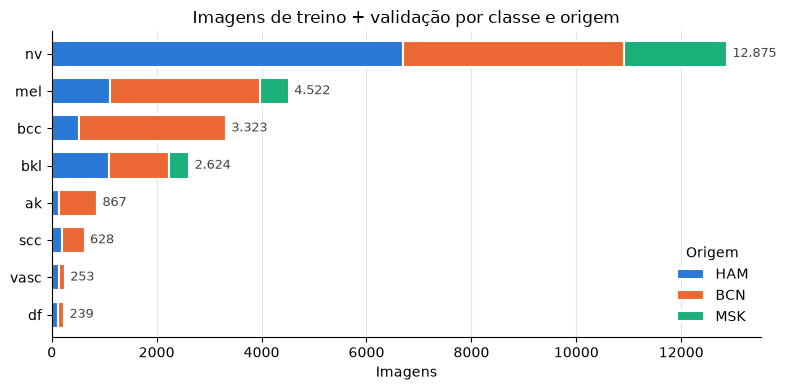

dx,ak,bcc,bkl,df,mel,nv,scc,vasc
source,,,,,,,,
HAM,1.3,5.1,11.0,1.1,11.1,66.9,2.0,1.4
BCN,5.9,22.6,9.2,1.0,23.0,33.9,3.5,0.9
MSK,0.0,0.0,13.3,0.0,19.0,67.7,0.0,0.0


In [5]:
# Treino + validação por classe e origem
SOURCES = ["HAM", "BCN", "MSK"]
SOURCE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

trainval = df[df["split"].isin(["train", "val"])]
counts = pd.crosstab(trainval["dx"], trainval["source"])[SOURCES]
counts = counts.loc[counts.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.barh(stacked=True, color=SOURCE_COLORS, edgecolor="white", linewidth=1.5, width=0.7, ax=ax)
for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 100, i, f"{total:,}".replace(",", "."), va="center", fontsize=9, color="#444")
ax.set(xlabel="Imagens", ylabel="", title="Imagens de treino + validação por classe e origem")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(title="Origem", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

# Proporção (%) de cada classe dentro de cada origem
display((pd.crosstab(trainval["source"], trainval["dx"], normalize="index") * 100).round(1).loc[SOURCES, CLASSES])

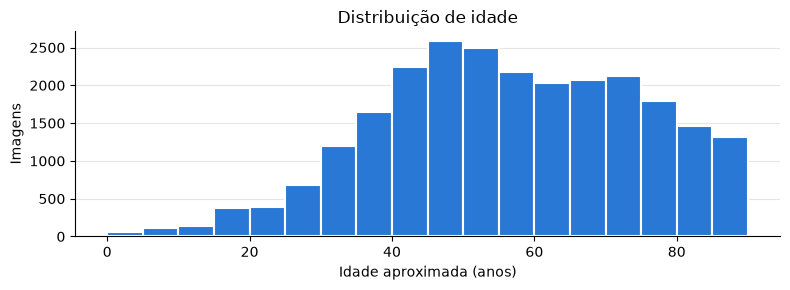

Faltantes (%):
age_approx     1.7
sex            1.5
site          10.2


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
site,,,,,,,,
(vazio),22,72,273,3,127,2049,6,31
anterior torso,92,1114,445,43,1331,3699,113,78
head/neck,598,1131,1001,0,880,767,174,36
lateral torso,0,0,6,0,14,34,0,0
lower extremity,66,462,412,138,796,2876,182,58
oral/genital,0,0,16,1,19,69,0,2
palms/soles,6,0,7,0,201,168,13,3
posterior torso,4,186,230,2,430,1888,25,22
upper extremity,79,358,234,52,724,1325,115,23


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
sex,,,,,,,,
(vazio),3,6,23,0,81,271,0,0
female,406,1317,1134,117,1980,6379,203,125
male,458,2000,1467,122,2461,6225,425,128


In [6]:
# Metadados clínicos (treino + validação)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(trainval["age_approx"].dropna(), bins=np.arange(0, 95, 5), color="#2a78d6", edgecolor="white", linewidth=1.5)
ax.set(xlabel="Idade aproximada (anos)", ylabel="Imagens", title="Distribuição de idade")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("Faltantes (%):")
print((trainval[["age_approx", "sex", "site"]].isna().mean() * 100).round(1).to_string())
display(pd.crosstab(trainval["site"].fillna("(vazio)"), trainval["dx"])[CLASSES])
display(pd.crosstab(trainval["sex"].fillna("(vazio)"), trainval["dx"])[CLASSES])

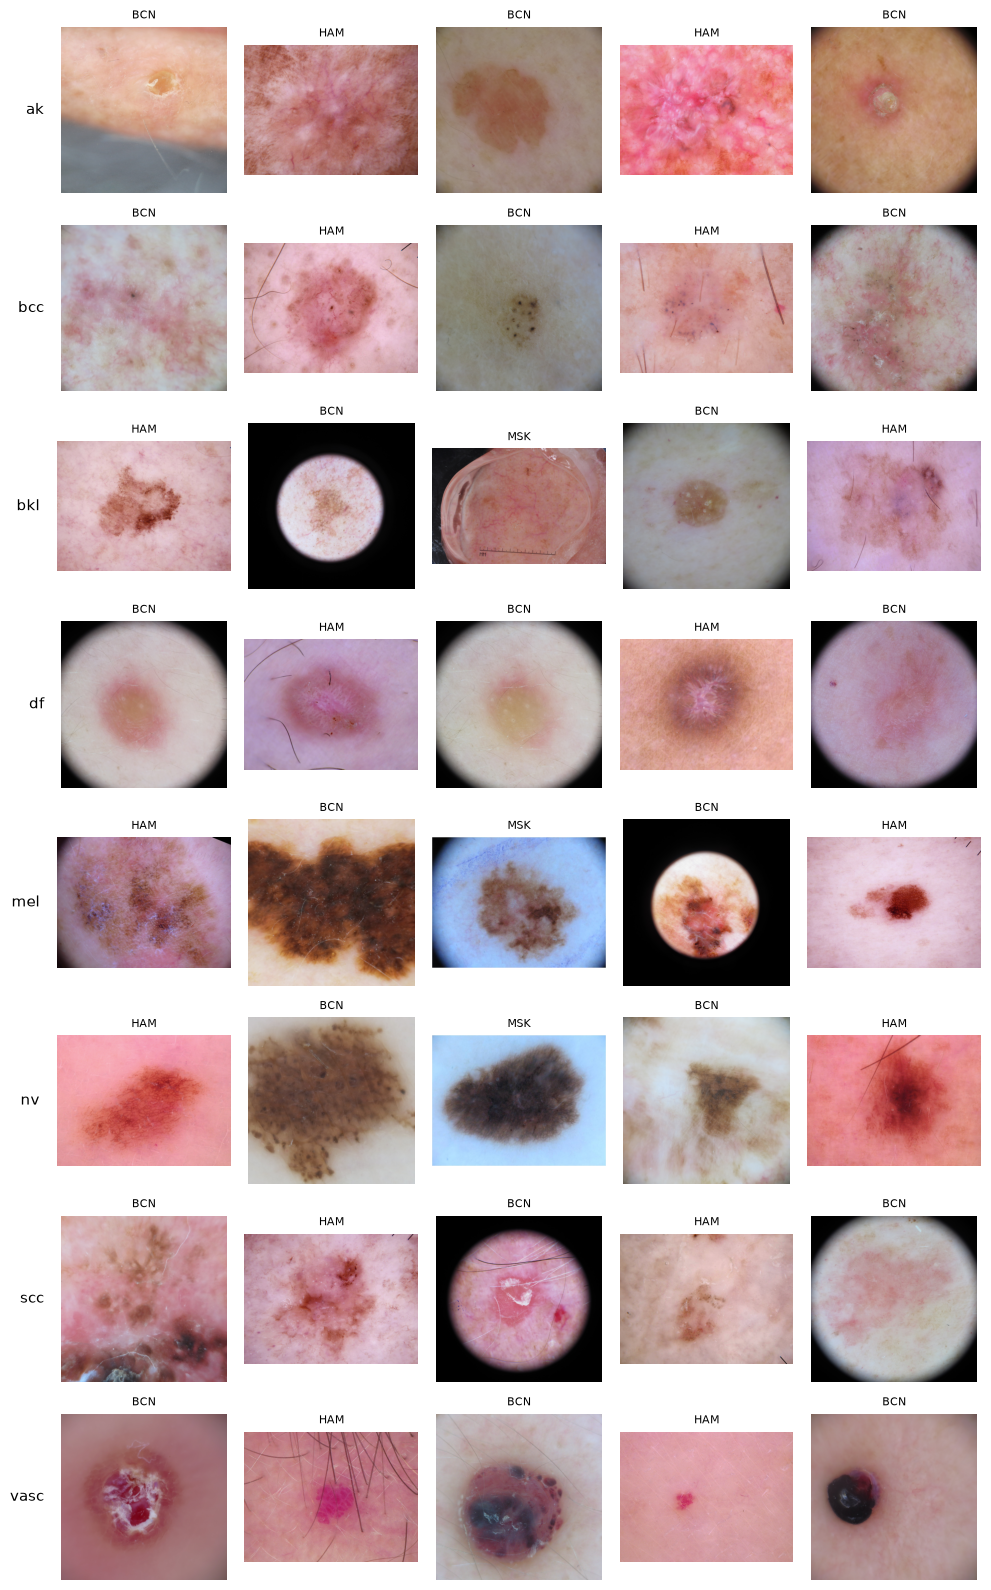

source
BCN                                   {(1024, 1024): 50}
HAM                                     {(600, 450): 50}
MSK    {(1024, 680): 19, (1024, 768): 10, (1024, 685)...
Name: size, dtype: object

In [7]:
# Exemplos de cada classe, misturando as origens
N_EXAMPLES = 5
fig, axes = plt.subplots(len(CLASSES), N_EXAMPLES, figsize=(2 * N_EXAMPLES, 2 * len(CLASSES)))
for row, dx in zip(axes, CLASSES):
    pool = train_df[train_df["dx"] == dx].groupby("source").head(N_EXAMPLES)
    sample = pool.sample(min(N_EXAMPLES, len(pool)), random_state=SEED)
    for ax in row:
        ax.axis("off")
    for ax, r in zip(row, sample.itertuples()):
        ax.imshow(Image.open(r.image_path))
        ax.set_title(r.source, fontsize=8)
    row[0].text(-0.1, 0.5, dx, transform=row[0].transAxes, ha="right", va="center", fontsize=11)
plt.tight_layout()
plt.show()

# Tamanho das imagens por origem (amostra)
sizes = train_df.groupby("source").sample(50, random_state=SEED)
sizes["size"] = [Image.open(p).size for p in sizes["image_path"]]
sizes.groupby("source")["size"].agg(lambda s: s.value_counts().head(3).to_dict())

## Composição do treino, da validação e do teste

In [8]:
# Remonta os conjuntos usando o mesmo código do treino, a partir do manifesto do repositório
from treinar_simulando_celular import CONJUNTOS, montar_tabela

treino_modelo, val_modelo, teste_celular = montar_tabela(CONJUNTOS["dermatoscopia+fotos"], max_nevos=6000, rapido=False)
conjuntos = pd.concat({"treino": treino_modelo, "validação": val_modelo, "teste celular": teste_celular}, names=["conjunto"]).reset_index("conjunto").reset_index(drop=True)
display(pd.crosstab(conjuntos["grupo"], conjuntos["conjunto"], margins=True)[["treino", "validação", "teste celular", "All"]])
pd.crosstab(conjuntos["dx"], conjuntos["conjunto"], margins=True)[["treino", "validação", "teste celular", "All"]]

conjunto,treino,validação,teste celular,All
grupo,,,,
anonima,69,14,0,83
hiba,0,0,345,345
isic2019_train,14813,3801,0,18614
isic2020,1921,901,0,2822
mednode,81,24,0,105
milk10k_dermatoscopia,3264,770,0,4034
milk10k_foto,3261,770,0,4031
mskcc,26,5,0,31
pad_ufes_20,0,0,2298,2298


conjunto,treino,validação,teste celular,All
dx,,,,
ak,910,165,747,1822
bcc,6384,1260,959,8603
bkl,3145,592,261,3998
df,275,50,22,347
mel,4981,914,117,6012
nv,6000,2955,297,9252
scc,1460,296,240,1996
vasc,280,53,0,333
All,23435,6285,2643,32363


# 2. Modelo

## Como o modelo foi construído

Uma única rede: **EfficientNetV2-B0 em 224 px** mais uma segunda entrada com 14 metadados (idade, sexo, região do corpo, com indicadores de faltante) e 8 saídas (logits). A construção teve duas etapas.

**Etapa 1: pesos de partida** (`modelos/pintas/pesos_de_partida.keras`). Transfer learning do ImageNet no treino do ISIC 2019 (21.486 imagens): primeiro só a cabeça, depois o ajuste fino da rede inteira com as BatchNormalization congeladas, AdamW (lr de pico 3e-4, weight decay 0,02), aquecimento + cosseno e parada antecipada. Pré-processamento com **Shades of Gray**, que uniformiza a cor entre aparelhos, e augmentation geométrica e de cor (`pipeline.augment`). Esses pesos não são mais um modelo do projeto, só o ponto de partida: em foto de celular eles desabam (AUC de melanoma 0,59).

**Etapa 2: adaptação para o celular** (`scripts/treinar_simulando_celular.py --conjunto dermatoscopia+fotos`), o que produz o modelo final (`modelos/pintas/melhor.keras`):

- **Treino**: 23.435 imagens sem nenhuma foto de celular, incluindo fotos clínicas de câmera. **Validação**: 6.285 imagens das mesmas fontes, que decide a época, o `tau` e o limiar.
- **Augmentation**: a do pipeline **mais** a simulação de celular (abaixo).
- **Otimização**: toda a rede treinável exceto BatchNormalization, AdamW (wd 0,02), lr 1e-4 com 1 época de aquecimento e cosseno, lote 32, até 8 épocas com parada antecipada (paciência 3). Melhor época: 7. Cerca de 2,5 h na CPU.
- **Decisão**: TTA de 8 vistas (4 rotações × espelhamento); ajuste de prior `log p − tau·log prior` com **tau = 1,1**; triagem pela soma de p(ak, bcc, mel, scc) ≥ **0,287**, o limiar de 95% de sensibilidade na validação.

**O que cada ingrediente rendeu** (no teste de celular):

| Variante | AUC melanoma | Acurácia balanceada |
|---|---|---|
| Pesos de partida | 0,593 | 30% |
| Só dermatoscopia + simulação | 0,735 | 40% |
| Dermatoscopia + fotos clínicas, sem simulação | 0,827 | 46% |
| **Dermatoscopia + fotos clínicas + simulação (final)** | **0,871** | **48%** |

A maior parte do ganho vem de pôr **fotos clínicas comuns** no treino; a simulação soma mais +0,044 de AUC por cima.

Para retreinar é preciso a base ampliada (ver README): `uv run scripts/treinar_simulando_celular.py --conjunto dermatoscopia+fotos`.

In [9]:
PASTA_MODELO = Path("modelos/pintas")
IMG_SIZE, BATCH_SIZE, TTA_VIEWS, CACHE_SIZE = 224, 32, 8, 288
CACHE_DIR = Path(os.environ.get("CACHE_DIR", DEFAULT_DIR.parent / f"lesoes_pele_cache_{CACHE_SIZE}"))

# Parâmetros de decisão, escolhidos na validação do treino (nenhuma imagem de teste)
PRIOR = np.array([910, 6384, 3145, 275, 4981, 6000, 1460, 280], dtype=float)  # classes no treino, ordem de CLASSES
LOG_PRIOR = np.log(PRIOR / PRIOR.sum())
TAU, LIMIAR_MALIGNO = 1.1, 0.287

rede_pintas = keras.models.load_model(PASTA_MODELO / "melhor.keras", compile=False)
print({k: tuple(v.shape) for k, v in zip(["image", "meta"], rede_pintas.inputs)}, "->", tuple(rede_pintas.output.shape))
print(f"{rede_pintas.count_params():,} parâmetros | tau {TAU} | limiar de triagem {LIMIAR_MALIGNO}")

{'image': (None, 224, 224, 3), 'meta': (None, 14)} -> (None, 8)
5,931,288 parâmetros | tau 1.1 | limiar de triagem 0.287


## A simulação de celular

`pipeline.simular_celular` é aplicada depois da augmentation comum, sorteando cada efeito por imagem:

| Ordem | Efeito | Chance | O que imita |
|---|---|---|---|
| 1 | recorte interno (70–90%) | 50% | tira a borda do dermatoscópio |
| 2 | afastar (lesão em 50–90% do quadro) | 40% | foto de mais longe |
| 3 | brilho, contraste, saturação e matiz fortes | 60% | luz ruim |
| 4 | balanço de branco (0,8–1,2 por canal) | 50% | luz amarela ou azulada |
| 5 | sombra em gradiente | 40% | sombra da mão, luz lateral |
| 6 | perda de resolução (25–70%) | 50% | sensor fraco, foto de longe |
| 7 | desfoque gaussiano (sigma 0,5–2,5) | 40% | foco ruim |
| 8 | ruído de sensor (sigma 3–14) | 50% | pouca luz |
| 9 | recompressão JPEG (qualidade 25–80) | 50% | WhatsApp e apps |

A célula seguinte executa o código de verdade em imagens do treino: na 1ª linha a original, nas outras duas sorteios da augmentation.

**Limitações observadas**: o fundo do efeito "afastar" sai como um retângulo acinzentado com borda marcada, que não lembra uma foto real; a augmentation comum ainda desenha a borda do dermatoscópio em 25% das imagens, o oposto do que se quer simular; e em alguns sorteios a lesão quase some, mantendo o rótulo. Corrigir isso exige retreinar, por isso fica nos próximos passos.

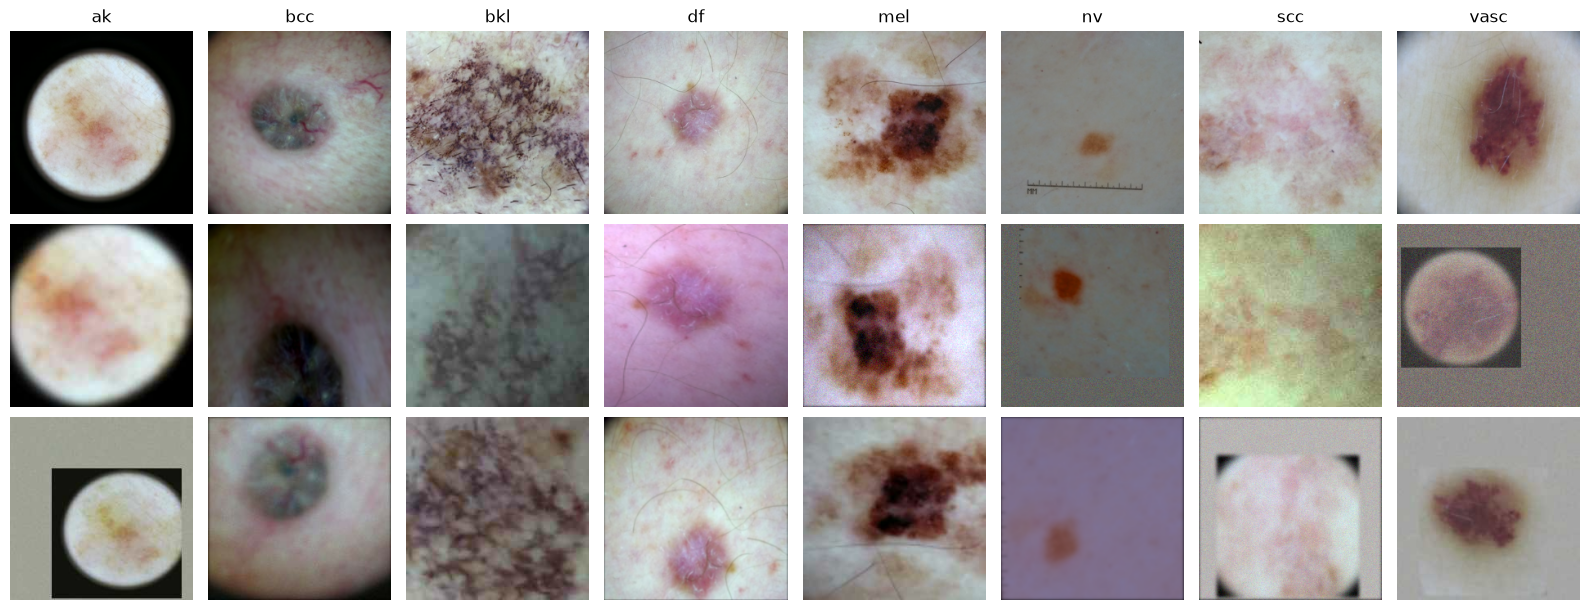

In [10]:
amostra = build_cache(train_df.groupby("dx").sample(1, random_state=SEED), CACHE_DIR, size=CACHE_SIZE)
keras.utils.set_random_seed(SEED)

fig, axes = plt.subplots(3, 8, figsize=(16, 6.2))
for j, (caminho, dx) in enumerate(zip(amostra["image_path"], amostra["dx"])):
    img = decode(caminho)
    axes[0, j].imshow(center_crop(img, IMG_SIZE).numpy().astype("uint8"))
    axes[0, j].set_title(dx)
    for i in (1, 2):
        axes[i, j].imshow(simular_celular(augment(img, IMG_SIZE), IMG_SIZE).numpy().astype("uint8"))
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

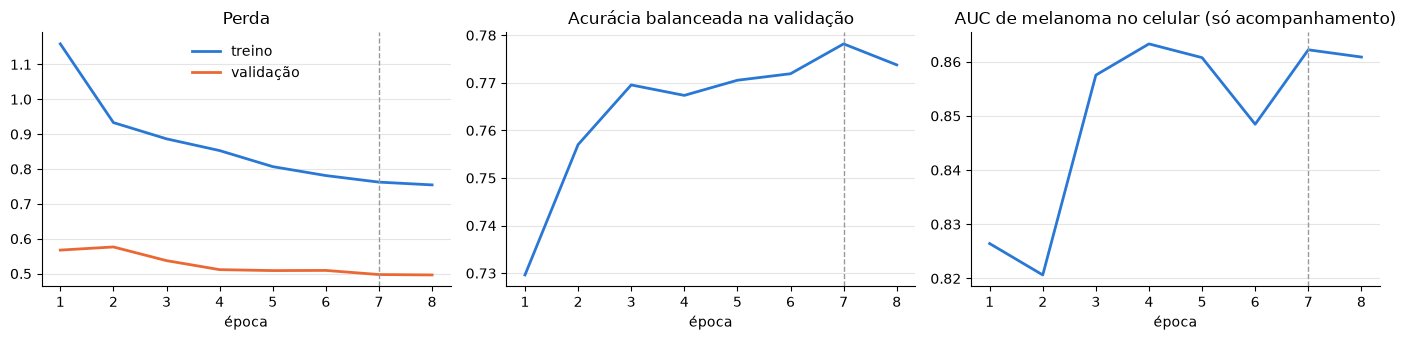

Melhor época (acurácia balanceada na validação): 7


In [11]:
# Curvas da etapa 2. A AUC no celular só era acompanhada: nunca escolheu época nem parâmetro
h = pd.read_csv(PASTA_MODELO / "historico.csv")
epoca = h["epoch"] + 1
melhor = epoca[h["val_bal_acc"].idxmax()]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(epoca, h["loss"], color="#2a78d6", lw=2, label="treino")
axes[0].plot(epoca, h["val_loss"], color="#eb6834", lw=2, label="validação")
axes[0].set(title="Perda", xlabel="época")
axes[0].legend(frameon=False)
axes[1].plot(epoca, h["val_bal_acc"], color="#2a78d6", lw=2)
axes[1].set(title="Acurácia balanceada na validação", xlabel="época")
axes[2].plot(epoca, h["celular_mel_auc_informativo"], color="#2a78d6", lw=2)
axes[2].set(title="AUC de melanoma no celular (só acompanhamento)", xlabel="época")
for a in axes:
    a.axvline(melhor, color="#999", ls="--", lw=1)
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e5e5e5")
plt.tight_layout()
plt.show()
print("Melhor época (acurácia balanceada na validação):", int(melhor))

# 3. Teste em dermatoscopia

Avaliação no **teste do ISIC 2018** (1.511 imagens, 7 classes), com TTA de 8 vistas. Nenhuma dessas imagens entra no treino nem na validação. `tau` e limiar vêm da validação do treino e foram aplicados aqui sem ajuste.

- **Métricas gerais e comparação com os pesos de partida.**
- **Relatório por classe e matriz de confusão.**
- **Triagem maligno × benigno** e a troca entre sensibilidade e especificidade.
- **Dermatologistas**: as mesmas imagens foram diagnosticadas por centenas de médicos (Tschandl et al., *Nature Medicine* 2020).
- **Uso do modelo salvo.**

In [12]:
MALIGNANT_8 = [CLASS_IDX[c] for c in ["ak", "bcc", "mel", "scc"]]
MALIGNANT_7 = [HAM_IDX[c] for c in ["akiec", "bcc", "mel"]]


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def adjust(p, tau=TAU):
    """Ajuste de logits: divide as probabilidades por prior**tau e renormaliza."""
    return softmax(np.log(p + 1e-12) - tau * LOG_PRIOR)


def to_ham(p):
    """8 classes -> 7 do HAM10000 (akiec = ak + scc), para comparar com o gabarito do teste."""
    return np.stack([p[:, CLASS_IDX["ak"]] + p[:, CLASS_IDX["scc"]] if c == "akiec" else p[:, CLASS_IDX[c]]
                     for c in HAM_CLASSES], axis=1)


salvos = np.load(PASTA_MODELO / "probs_isic2018.npz")
teste = df[df["split"] == "test"].set_index("file_id").loc[salvos["ids_test"].astype(str)].reset_index()
y_test = teste["dx_ham"].map(HAM_IDX).values
raw, ajustada = to_ham(salvos["test"]), to_ham(adjust(salvos["test"]))
pred = ajustada.argmax(1)

# Métricas do modelo recalculadas aqui; os pesos de partida vêm do CSV da comparação
comparacao = pd.read_csv(PASTA_MODELO / "comparacao_dermatoscopia.csv").set_index("modelo")
recalculado = {"acuracia": accuracy_score(y_test, raw.argmax(1)), "acuracia_balanceada": balanced_accuracy_score(y_test, pred),
               "auc_macro": roc_auc_score(y_test, raw, multi_class="ovr", labels=range(len(HAM_CLASSES))),
               "maligno_auc": roc_auc_score(np.isin(y_test, MALIGNANT_7), raw[:, MALIGNANT_7].sum(1))}
for k, v in recalculado.items():
    assert abs(comparacao.loc["modelo do projeto (simulação de celular)", k] - v) < 1e-9, k
comparacao.T.round(3)

modelo,pesos de partida (só ISIC 2019),modelo do projeto (simulação de celular)
imagens,1511.000,1511.000
melanomas,171.000,171.000
tau,0.900,1.100
limiar,0.045,0.287
acuracia,0.822,0.828
acuracia_balanceada,0.743,0.750
auc_macro,0.961,0.966
mel_auc,0.928,0.931
maligno_auc,0.943,0.945
mel_sensibilidade,0.503,0.620


**Resultado.** Na dermatoscopia o modelo **empata** com os pesos de partida: as diferenças ficam dentro do ruído (IC 95% por bootstrap: acurácia −1,1 a +2,3 pontos; acurácia balanceada −2,4 a +3,6 pontos; AUC maligno × benigno −0,006 a +0,012). Ganhou o celular sem perder a dermatoscopia.

O que muda é o **ponto de operação**: a sensibilidade de melanoma como classe sobe de 50% para 62%, mas a triagem deixa passar mais malignos (26 contra 13 de 307), em troca de 10 pontos a mais de especificidade. Veja a tabela de limiares abaixo.

              precision    recall  f1-score   support

       akiec      0.449     0.721     0.554        43
         bcc      0.795     0.667     0.725        93
         bkl      0.770     0.631     0.694       217
          df      0.473     0.795     0.593        44
         mel      0.582     0.620     0.601       171
          nv      0.927     0.903     0.915       908
        vasc      0.711     0.914     0.800        35

    accuracy                          0.809      1511
   macro avg      0.672     0.750     0.697      1511
weighted avg      0.825     0.809     0.813      1511



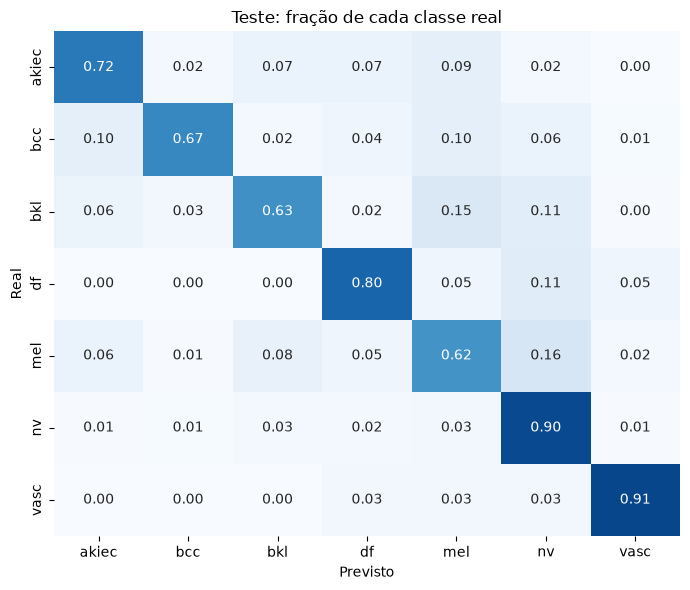

In [13]:
# Relatório por classe e matriz de confusão (decisão ajustada pelo prior)
labels = list(range(len(HAM_CLASSES)))
print(classification_report(y_test, pred, labels=labels, target_names=HAM_CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=HAM_CLASSES, yticklabels=HAM_CLASSES, ax=ax)
ax.set(xlabel="Previsto", ylabel="Real", title="Teste: fração de cada classe real")
plt.tight_layout()
plt.show()

In [14]:
# Triagem "maligno ou não" (mel, bcc, akiec). O limiar vem da validação; a tabela mostra a troca
# entre sensibilidade e especificidade. A validação aqui é a parte só de dermatoscopia (ISIC 2019).
val_salva = np.load(PASTA_MODELO / "probs_val_dermatoscopia.npz")
y_val = np.array([CLASS_IDX[d] for d in val_salva["dx_val"].astype(str)])
score_val, mal_val = val_salva["val"][:, MALIGNANT_8].sum(1), np.isin(y_val, MALIGNANT_8)
score_test, mal_test = raw[:, MALIGNANT_7].sum(1), np.isin(y_test, MALIGNANT_7)

linhas = []
for limiar in [0.10, 0.15, 0.20, LIMIAR_MALIGNO, 0.40, 0.50]:
    linhas.append({"limiar": limiar, "sensibilidade (validação)": (score_val[mal_val] >= limiar).mean(),
                   "sensibilidade (teste)": (score_test[mal_test] >= limiar).mean(),
                   "especificidade (teste)": (score_test[~mal_test] < limiar).mean(),
                   "malignas perdidas (teste)": int((score_test[mal_test] < limiar).sum())})
print(f"AUC maligno x benigno no teste: {roc_auc_score(mal_test, score_test):.3f}")
pd.DataFrame(linhas).set_index("limiar").round(3)

AUC maligno x benigno no teste: 0.945


,sensibilidade (validação),sensibilidade (teste),especificidade (teste),malignas perdidas (teste)
limiar,,,,
0.100,0.994,0.990,0.648,3
0.150,0.986,0.971,0.699,9
0.200,0.975,0.948,0.760,16
0.287,0.958,0.915,0.832,26
0.400,0.922,0.844,0.885,48
0.500,0.880,0.788,0.924,65


O limiar **0,287** dá 95,8% de sensibilidade na validação, mas 91,5% no teste: a queda vem da mudança de base (o teste é todo HAM10000), e não do limiar. Recalcular o limiar só em dermatoscopia não ajudou (0,314, sensibilidade de 89,6% no teste). Limiares mais baixos da tabela sobem a sensibilidade à custa de especificidade; essa escolha não foi feita olhando o teste, e por isso o 0,287 foi mantido.

In [15]:
# Dermatologistas nas mesmas imagens do teste (Tschandl et al., Nature Medicine 2020): cada
# linha do CSV é um diagnóstico de um médico, sem e com o apoio da IA daquele estudo.
READERS_CSV = Path(os.environ.get(
    "READERS_CSV",
    Path.cwd().parent / "dataverse_files" / "ISIC2018_Task3_Test_NatureMedicine_AI_Interaction_Benefit.csv"))
if READERS_CSV.exists():
    nm = pd.read_csv(READERS_CSV, decimal=",")
    truth = teste.set_index("image_id")["dx_ham"].map(HAM_IDX)
    nm = nm[nm["image_id"].isin(truth.index)]
    y_nm = nm["image_id"].map(truth).values
    ours = pd.Series(pred, index=teste["image_id"].values)

    def answers(prefix):
        return nm[[f"{prefix}_{c}" for c in HAM_CLASSES]].values.argmax(1)

    comp = {
        "Dermatologistas sem IA": answers("user_dx_without_interaction"),
        "Dermatologistas com a IA do estudo": answers("user_dx_with_interaction"),
        "IA do estudo": answers("prob_m_dx"),
        "Nosso modelo": nm["image_id"].map(ours).values,
    }
    print(f"{len(nm)} diagnósticos em {nm['image_id'].nunique()} imagens do teste")
    display(pd.DataFrame({k: {"acurácia": accuracy_score(y_nm, v),
                              "acurácia balanceada": balanced_accuracy_score(y_nm, v)}
                          for k, v in comp.items()}).T.round(3))
else:
    print("CSV dos dermatologistas não encontrado:", READERS_CSV)

3762 diagnósticos em 1412 imagens do teste


,acurácia,acurácia balanceada
Dermatologistas sem IA,0.694,0.714
Dermatologistas com a IA do estudo,0.744,0.754
IA do estudo,0.782,0.777
Nosso modelo,0.763,0.750


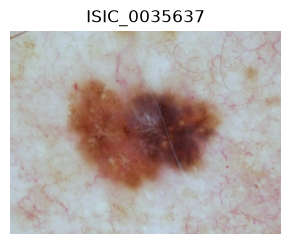

Diagnóstico real: Melanoma
Classes mais prováveis:
  Melanoma                          93.1%
  Nevo melanocítico                  6.2%
  Dermatofibroma                     0.3%
Triagem: probabilidade de malignidade 92.4% (limiar 28.7%) -> SUSPEITA, encaminhar para avaliação


In [16]:
# Usando o modelo salvo: classifica uma imagem do teste (aqui, um melanoma), como seria na prática
def view_tta(x, k):
    img = tf.image.rot90(x["image"], k % 4)
    return {**x, "image": tf.image.flip_left_right(img) if k >= 4 else img}


def predict_tta(model, data, views=TTA_VIEWS):
    ds = make_ds(data, IMG_SIZE, BATCH_SIZE, labels=None, use_meta=True)
    return sum(softmax(model.predict(ds.map(lambda x, k=k: view_tta(x, k)), verbose=0)) for k in range(views)) / views


exemplo = build_cache(teste[teste["dx_ham"] == "mel"].sample(1, random_state=SEED), CACHE_DIR, size=CACHE_SIZE)
p = predict_tta(rede_pintas, exemplo)
p_adj = adjust(p)[0]
score = p[0, MALIGNANT_8].sum()

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(Image.open(exemplo["image_path"].iloc[0]))
ax.set_title(exemplo["file_id"].iloc[0])
ax.axis("off")
plt.show()

print("Diagnóstico real:", DX_NAMES[exemplo["dx_ham"].iloc[0]])
print("Classes mais prováveis:")
for i in np.argsort(p_adj)[::-1][:3]:
    print(f"  {DX_NAMES[CLASSES[i]]:<32} {p_adj[i]:6.1%}")
print(f"Triagem: probabilidade de malignidade {score:.1%} (limiar {LIMIAR_MALIGNO:.1%}) ->",
      "SUSPEITA, encaminhar para avaliação" if score >= LIMIAR_MALIGNO else "baixa suspeita")

# 4. Teste em fotos de celular

O uso final começa por uma **foto de celular**, sem lente. A lente do dermatoscópio dá textura fina, cor calibrada e borda preta; o celular tem foco ruim, ruído, compressão, sombra e balanço de branco errado. Por isso os pesos de partida, ajustados só em dermatoscopia, desabam aqui.

O teste são as duas bases públicas com celular confirmado, **PAD-UFES-20** (Brasil, 2.298 fotos) e **HIBA** (Argentina, 345 fotos), usadas inteiras: 2.643 fotos, 117 melanomas, medidas com TTA. Tudo abaixo é lido das previsões salvas em `modelos/pintas/previsoes_celular.csv`.

**Cuidado na leitura:** as três variantes de treino da tabela da seção 2 foram comparadas neste mesmo teste, e a melhor foi a escolhida. Época, `tau` e limiar vieram só da validação, mas a escolha da variante viu o teste, então o resultado pode estar levemente otimista.

In [17]:
comp = pd.read_csv(PASTA_MODELO / "comparacao.csv")
comp["modelo"] = comp["modelo"].str.replace("antes (Felipe)", "pesos de partida", regex=False).str.replace("depois (B_dermatoscopia+fotos)", "modelo do projeto", regex=False)
cols = ["modelo", "conjunto", "imagens", "melanomas", "acuracia", "acuracia_balanceada", "mel_sensibilidade",
        "mel_precisao", "mel_auc", "maligno_auc", "triagem_sensibilidade", "triagem_especificidade"]
comp[cols].set_index(["conjunto", "modelo"]).sort_index(level=0, sort_remaining=False).round(3)

imagens  melanomas  acuracia  \
conjunto                     modelo                                            
celular (PAD-UFES-20 + HIBA) pesos de partida      2643        117     0.315   
                             modelo do projeto     2643        117     0.389   
hiba                         pesos de partida       345         65     0.304   
                             modelo do projeto      345         65     0.406   
pad_ufes_20                  pesos de partida      2298         52     0.317   
                             modelo do projeto     2298         52     0.386   

                                                acuracia_balanceada  \
conjunto                     modelo                                   
celular (PAD-UFES-20 + HIBA) pesos de partida                 0.303   
                             modelo do projeto                0.478   
hiba                         pesos de partida                 0.279   
                             modelo do projeto                0.428   
pad_ufes_20                  pesos de partida                 0.362   
                             modelo do projeto                0.476   

                                                mel_sensibilidade  \
conjunto                     modelo                                 
celular (PAD-UFES-20 + HIBA) pesos de partida               0.222   
                             modelo do projeto              0.504   
hiba                         pesos de partida               0.200   
                             modelo do projeto              0.369   
pad_ufes_20                  pesos de partida               0.250   
                             modelo do projeto              0.673   

                                                mel_precisao  mel_auc  \
conjunto                     modelo                                     
celular (PAD-UFES-20 + HIBA) pesos de partida          0.068    0.593   
                             modelo do projeto         0.224    0.871   
hiba                         pesos de partida          0.406    0.643   
                             modelo do projeto         0.462    0.817   
pad_ufes_20                  pesos de partida          0.037    0.644   
                             modelo do projeto         0.166    0.915   

                                                maligno_auc  \
conjunto                     modelo                           
celular (PAD-UFES-20 + HIBA) pesos de partida         0.845   
                             modelo do projeto        0.868   
hiba                         pesos de partida         0.792   
                             modelo do projeto        0.833   
pad_ufes_20                  pesos de partida         0.850   
                             modelo do projeto        0.872   

                                                triagem_sensibilidade  \
conjunto                     modelo                                     
celular (PAD-UFES-20 + HIBA) pesos de partida                   0.921   
                             modelo do projeto                  0.966   
hiba                         pesos de partida                   0.865   
                             modelo do projeto                  0.926   
pad_ufes_20                  pesos de partida                   0.928   
                             modelo do projeto                  0.971   

                                                triagem_especificidade  
conjunto                     modelo                                     
celular (PAD-UFES-20 + HIBA) pesos de partida                    0.491  
                             modelo do projeto                   0.414  
hiba                         pesos de partida                    0.525  
                             modelo do projeto                   0.426  
pad_ufes_20                  pesos de partida                    0.484  
                             modelo do projeto                   0.411

**Resultado.** IC 95% da melhora por bootstrap pareado: AUC de melanoma +0,23 a +0,32; acurácia balanceada +14 a +21 pontos; acurácia +5 a +9 pontos; AUC maligno × benigno +0,01 a +0,04. A melhora é real, mas o modelo ainda é modesto para decidir uma classe: a acurácia em celular fica em 39%.

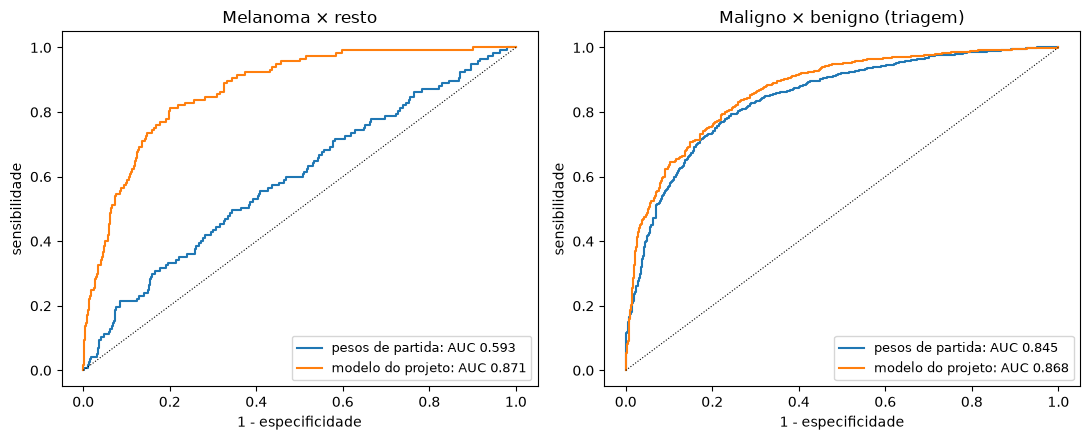

,sensibilidade,especificidade,melanomas perdidos,benignos encaminhados
limiar,,,,
0.287,0.966,0.412,15,341
0.400,0.941,0.540,23,267
0.500,0.907,0.617,33,222
0.600,0.869,0.690,43,180
0.700,0.802,0.764,57,137


In [18]:
from sklearn.metrics import roc_curve

prev = pd.read_csv(PASTA_MODELO / "previsoes_celular.csv")
y_cel = prev["dx"].map(CLASS_IDX).values
P_cel = {"pesos de partida": prev[[f"antes_p_{c}" for c in CLASSES]].values,
         "modelo do projeto": prev[[f"depois_p_{c}" for c in CLASSES]].values}
mel_cel = y_cel == CLASS_IDX["mel"]
mal_cel = np.isin(y_cel, MALIGNANT_8)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for nome, p in P_cel.items():
    for ax, (alvo, score, titulo) in zip(axes, [(mel_cel, p[:, CLASS_IDX["mel"]], "Melanoma × resto"),
                                               (mal_cel, p[:, MALIGNANT_8].sum(1), "Maligno × benigno (triagem)")]):
        fpr, tpr, _ = roc_curve(alvo, score)
        ax.plot(fpr, tpr, label=f"{nome}: AUC {roc_auc_score(alvo, score):.3f}")
        ax.set(xlabel="1 - especificidade", ylabel="sensibilidade", title=titulo)
for ax in axes:
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

# Triagem: o limiar escolhido na validação (dermatoscopia) fica agressivo no celular; a tabela
# mostra a troca sensibilidade × especificidade, que quem usa pode escolher
score_cel = P_cel["modelo do projeto"][:, MALIGNANT_8].sum(1)
linhas = []
for thr_ in [LIMIAR_MALIGNO, 0.4, 0.5, 0.6, 0.7]:
    enc = score_cel >= thr_
    linhas.append({"limiar": thr_, "sensibilidade": enc[mal_cel].mean(), "especificidade": (~enc[~mal_cel]).mean(),
                   "melanomas perdidos": int((mel_cel & ~enc).sum()), "benignos encaminhados": int((~mal_cel & enc).sum())})
pd.DataFrame(linhas).set_index("limiar").round(3)

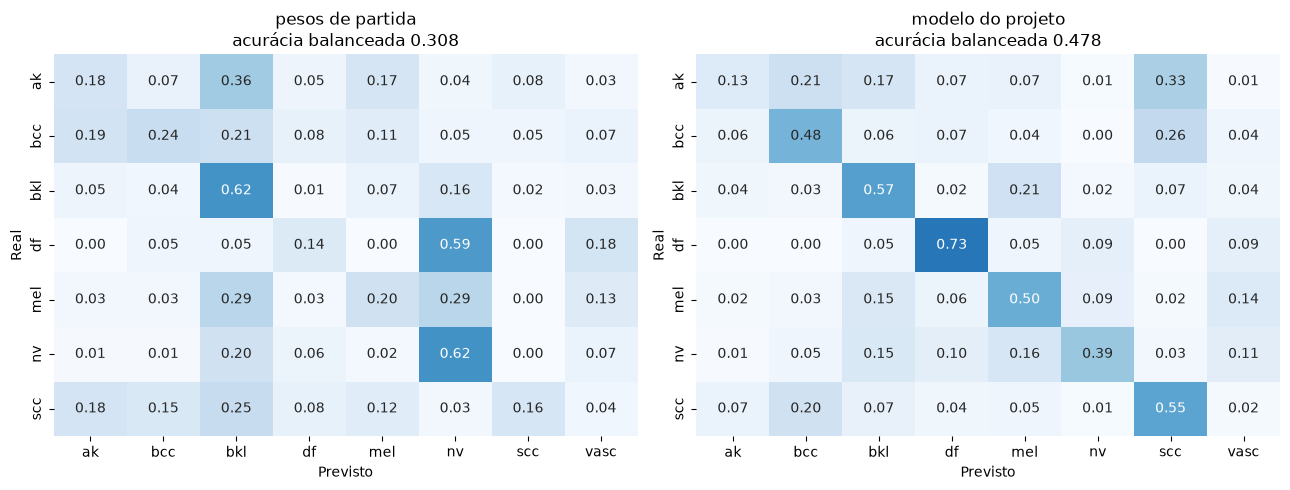

              precision    recall  f1-score   support

          ak      0.541     0.133     0.213       747
         bcc      0.663     0.477     0.555       959
         bkl      0.359     0.567     0.440       261
          df      0.088     0.727     0.158        22
         mel      0.224     0.504     0.311       117
          nv      0.806     0.391     0.526       297
         scc      0.200     0.550     0.294       240

   micro avg      0.406     0.389     0.397      2643
   macro avg      0.412     0.478     0.356      2643
weighted avg      0.548     0.389     0.406      2643



In [19]:
# Matriz de confusão nas fotos de celular (decisão ajustada pelo prior do treino, tau escolhido na validação).
# O teste não tem lesão vascular, por isso a linha vasc fica de fora.
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")  # vasc não existe no teste


presentes = [i for i in range(len(CLASSES)) if (y_cel == i).any()]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, p) in zip(axes, P_cel.items()):
    pred_cel = adjust(p).argmax(1)
    cm_cel = confusion_matrix(y_cel, pred_cel, labels=list(range(len(CLASSES))), normalize="true")[presentes]
    sns.heatmap(cm_cel, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASSES, yticklabels=[CLASSES[i] for i in presentes], ax=ax)
    ax.set(xlabel="Previsto", ylabel="Real",
           title=f"{nome}\nacurácia balanceada {balanced_accuracy_score(y_cel, pred_cel):.3f}")
plt.tight_layout()
plt.show()

pred_cel = adjust(P_cel["modelo do projeto"]).argmax(1)
print(classification_report(y_cel, pred_cel, labels=presentes, target_names=[CLASSES[i] for i in presentes],
                            digits=3, zero_division=0))

# Parte 2: triagem em duas etapas

Até aqui, o modelo de pintas classifica lesões em dermatoscopia e em foto de celular. Esta parte o amplia para **erupções, alergias e infecções de pele em fotos de celular**, e dá uma orientação de próximo passo para cada caso.

**Este é um projeto acadêmico de apoio à triagem. O resultado é sempre uma sugestão ou orientação, nunca um diagnóstico.**

Para rodar esta parte, é preciso ter a pasta `data_Alergias` (SCIN) ao lado do repositório e a base de pintas da Parte 1. O PAD-UFES-20 é baixado automaticamente, e as redes treinadas já vêm em `modelos/triagem/`, então o treino é pulado.

| Etapa | O que é feito |
|---|---|
| 1. Exploração | entender o SCIN: colunas, rótulos, classes, tipos de pele |
| 2. Limpeza | extrair imagens, remover duplicatas e casos sem rótulo confiável |
| 3. Splits | treino, validação e teste por caso, sem vazamento |
| PAD-UFES-20 | fotos de celular de pintas, que faltavam no SCIN |
| 4. Arquitetura e treino | detector de tipo de foto, roteador e especialista |
| 5. Orientação | urgência e perguntas de alerta, só por regras |
| 6. Avaliação | métricas no teste, erro grave, calibração, tipo de pele, Grad-CAM |

In [20]:
import ast
from collections import Counter
import glob
import hashlib
import io
import json
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache

import imagehash
import pyarrow.parquet as pq
import yaml
from IPython.display import display
from PIL import ImageOps, UnidentifiedImageError
from scipy.optimize import minimize_scalar
from scipy.special import softmax as scipy_softmax
from sklearn.metrics import recall_score
from sklearn.model_selection import StratifiedGroupKFold

from pipeline import center_crop, decode, meta_features, shades_of_gray
from prepare_data import CLASSES, DEFAULT_DIR, DX_NAMES, load_labels

SEED = 42
keras.utils.set_random_seed(SEED)

REPO = Path.cwd()
# dados brutos ficam ao lado do repositório; bases prontas e cache, em ~/datasets, fora do repositório
SCIN_RAW_DIR = Path(os.environ.get("SCIN_RAW", REPO.parent / "data_Alergias"))
SCIN_DIR = DEFAULT_DIR.parent / "scin"
PAD_RAW_DIR = DEFAULT_DIR.parent / "pad_ufes_raw"
PAD_DIR = DEFAULT_DIR.parent / "pad_ufes"
SPLITS = REPO / "splits"
SCIN_SPLITS, PAD_SPLITS = SPLITS / "scin_v1.csv", SPLITS / "pad_v1.csv"
MODELS = REPO / "modelos" / "triagem"       # as redes treinadas vêm no repositório
THRESHOLDS = MODELS / "limiares.json"
WORK_DIR = DEFAULT_DIR.parent / "modelos" / "triagem_treino"
RELATORIOS = REPO / "relatorios"
FIGURAS = RELATORIOS / "figuras"

BLUE, ORANGE = "#2a78d6", "#eb6834"
print("SCIN:", SCIN_RAW_DIR, "| modelos:", MODELS)

SCIN: C:\Users\felip\OneDrive\Documentos\InsperAI\ProjetoFinal\data_Alergias | modelos: C:\Users\felip\OneDrive\Documentos\InsperAI\ProjetoFinal\ProjetoFinal-InsperAI-FelipeGava-LucasBriones\modelos\triagem


## Etapa 1: exploração do SCIN (`data_Alergias`)

Base usada para ampliar a triagem para lesões além das pintas. **Este é um projeto acadêmico de apoio à triagem: o resultado é uma sugestão ou orientação, não um diagnóstico.**

### Conclusões

- **É o SCIN, do Google**, com imagens embutidas nos parquets, mas **falta um dos 26 arquivos** (`train-00000-of-00026.parquet`). Há 25 arquivos, 4.839 casos e 9.998 imagens.
- **Cada caso tem de 1 a 3 fotos de celular da mesma lesão** (39% têm 1; 45% têm 3). É por isso que a divisão treino/validação/teste é por `case_id`.
- **Há diagnóstico prévio em 61% dos casos** (2.947 com rótulo e 1.892 sem). Quase todos os casos sem rótulo foram marcados como sem qualidade de imagem suficiente.
- **Os rótulos são incertos.** Cada caso tem em média mais de uma condição possível: só 665 têm condição única, e o peso mediano da condição principal é 0,55. Em 886 casos há empate no topo. A confiança mediana dos dermatologistas é 2,5 de 5. Isso favorece testar **rótulos suaves**.
- **Cauda longa**: 205 condições como principal, só 20 com pelo menos 30 casos. Eczema, dermatite de contato, urticária e picada de inseto dominam.
- **Pele**: predominam tons claros (Monk 2 e 3), e os tons 8 a 10 são raros. Fitzpatrick falta em 50% dos casos e a idade em 57%. O desempenho em pele escura terá pouca evidência.
- **Queimaduras: praticamente não há** (32 citações, 7 como condição principal e só 4 casos depois da limpeza). A classe fica **desativada** até haver uma base específica.
- **Feridas: poucas** (40 como principal; 30 casos depois da limpeza). **Pintas: quase nenhuma** (22 como principal; 17 depois da limpeza). O SCIN não serve, sozinho, para ensinar o que é pinta.
- **Base limpa**: 5.434 imagens de 2.581 casos, em 16 condições + `outras_condicoes`.
- **Nenhuma duplicata** entre o SCIN e as bases de pintas (ISIC 2019/2018, HAM10000).

Todas as fotos são de pessoas reais, de-identificadas pelo Google. Os exemplos abaixo são só de close, em adultos, sem tronco nem região genital.

In [21]:
GROUP_TERMS = {
    "ferida": ("wound", "ulcer", "abrasion", "laceration", "traumatic blister"),   # vem antes: "friction burn" é ferida
    "queimadura": ("burn",),
    "pinta": ("melanocytic nevus", "atypical nevus", "melanoma", "lentigo", "basal cell", "squamous cell",
              "seborrheic keratosis", "actinic keratosis", "dysplastic nevus", "blue nevus", "keratoacanthoma"),
}


def group_of(condition):
    if condition is None or pd.isna(condition):
        return None
    name = condition.lower()
    for group, terms in GROUP_TERMS.items():
        if any(t in name for t in terms):
            return group
    return "erupcao_alergia"

In [22]:
# só as colunas de texto: as imagens embutidas ficam de fora, para não carregar 12 GB
files = sorted(SCIN_RAW_DIR.glob("*.parquet"))
faltando = sorted({f"train-{i:05d}-of-00026.parquet" for i in range(26)} - {f.name for f in files})
names = pq.ParquetFile(files[0]).schema_arrow.names
text_cols = [c for c in names if not (c.startswith("image_") and c.endswith("_path"))]
scin_bruto = pd.concat([pq.read_table(f, columns=text_cols).to_pandas() for f in files], ignore_index=True)
print(f"{len(files)} de 26 arquivos | faltando: {faltando}")
print(f"{len(scin_bruto)} casos, {scin_bruto['case_id'].nunique()} case_id únicos, {len(names)} colunas")

25 de 26 arquivos | faltando: ['train-00000-of-00026.parquet']
4839 casos, 4839 case_id únicos, 73 colunas


### Colunas

Cada linha é um **caso** (`case_id`), um envio feito por uma pessoa nos EUA, por fotos de celular, com até 3 imagens da mesma lesão.

In [23]:
grupos = {
    "Identificação": ["case_id", "source", "release", "year"],
    "Imagens (bytes + nome) e tipo de foto": [c for c in names if c.startswith("image_")],
    "Demografia autodeclarada": ["age_group", "sex_at_birth", "fitzpatrick_skin_type", "combined_race"]
        + [c for c in names if c.startswith("race_ethnicity_")],
    "Sintomas, textura, região do corpo e duração": [c for c in names if c.startswith(("textures_", "body_parts_", "condition_symptoms_", "other_symptoms_"))]
        + ["related_category", "condition_duration"],
    "Rótulos de dermatologistas (condição)": ["weighted_skin_condition_label", "dermatologist_skin_condition_on_label_name", "dermatologist_skin_condition_confidence"]
        + [c for c in names if c.startswith("dermatologist_gradable_for_skin")],
    "Tipo de pele avaliado por especialistas": [c for c in names if "fitzpatrick_skin_type_" in c and c.startswith("dermatologist")] + [c for c in names if "monk" in c],
}
pd.DataFrame({"grupo": grupos.keys(), "colunas": [len(v) for v in grupos.values()],
              "exemplos": [", ".join(v[:3]) for v in grupos.values()]})

,grupo,colunas,exemplos
0,Identificação,4,"case_id, source, release"
1,Imagens (bytes + nome) e tipo de foto,6,"image_1_path, image_2_path, image_3_path"
2,Demografia autodeclarada,14,"age_group, sex_at_birth, fitzpatrick_skin_type"
3,"Sintomas, textura, região do corpo e duração",33,"textures_raised_or_bumpy, textures_flat, textu..."
4,Rótulos de dermatologistas (condição),6,"weighted_skin_condition_label, dermatologist_s..."
5,Tipo de pele avaliado por especialistas,10,dermatologist_gradable_for_fitzpatrick_skin_ty...


### Há diagnóstico prévio?

Cada dermatologista indica até 3 condições, com confiança de 1 a 5. `weighted_skin_condition_label` junta tudo em pesos que somam 1 por caso: um caso pode ter várias condições possíveis.

Com rótulo de dermatologista: 2947 (60.9%) | sem rótulo: 1892
Condições possíveis por caso: {1: 665, 2: 775, 3: 1193, 4: 157, 5: 110, 6: 36, 7: 8, 8: 3}
Dermatologistas por caso: {1: 645, 2: 745, 3: 1116, 4: 125, 5: 114, 6: 106, 7: 59, 8: 28, 9: 9}
Peso da condição principal: mediana 0.55; casos com condição única: 665; empate no topo: 886


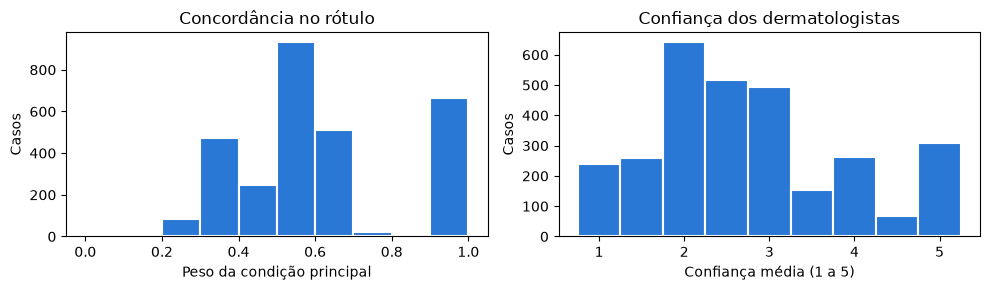

Avaliável (1º dermatologista): {'DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT': 2939, 'NO_IMAGE_QUALITY_INSUFFICIENT': 1843, 'YES_IMAGE_QUALITY_SUFFICIENT_NO_DISCERNIBLE_PATHOLOGY': 57}


In [24]:
pesos = scin_bruto["weighted_skin_condition_label"].map(ast.literal_eval)
conf = scin_bruto["dermatologist_skin_condition_confidence"].map(ast.literal_eval)
tem = pesos.map(len) > 0
print(f"Com rótulo de dermatologista: {tem.sum()} ({tem.mean():.1%}) | sem rótulo: {(~tem).sum()}")
print("Condições possíveis por caso:", pesos[tem].map(len).value_counts().sort_index().to_dict())
print("Dermatologistas por caso:", conf[tem].map(len).value_counts().sort_index().to_dict())

peso_max = pesos[tem].map(lambda d: max(d.values()))
conf_media = conf[tem].map(np.mean)
empates = pesos[tem].map(lambda d: sum(v == max(d.values()) for v in d.values()) > 1).sum()
print(f"Peso da condição principal: mediana {peso_max.median():.2f}; casos com condição única: {(peso_max == 1).sum()}; empate no topo: {empates}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3))
a1.hist(peso_max, bins=np.arange(0, 1.05, 0.1), color=BLUE, edgecolor="white", linewidth=1.5)
a1.set(xlabel="Peso da condição principal", ylabel="Casos", title="Concordância no rótulo")
a2.hist(conf_media, bins=np.arange(0.75, 5.5, 0.5), color=BLUE, edgecolor="white", linewidth=1.5)
a2.set(xlabel="Confiança média (1 a 5)", ylabel="Casos", title="Confiança dos dermatologistas")
plt.tight_layout(); plt.show()

aval = scin_bruto["dermatologist_gradable_for_skin_condition_1"].value_counts().to_dict()
print("Avaliável (1º dermatologista):", aval)

### Imagens por caso

In [25]:
shots = scin_bruto[[f"image_{i}_shot_type" for i in (1, 2, 3)]]
n = shots.notna().sum(axis=1)
print("Imagens por caso:", n.value_counts().sort_index().to_dict(), "| total:", int(n.sum()))
print("Tipo de foto:", pd.Series(shots.values.ravel()).value_counts().to_dict())

Imagens por caso: {1: 1871, 2: 775, 3: 2193} | total: 10000
Tipo de foto: {'CLOSE_UP': 4835, 'AT_AN_ANGLE': 2901, 'AT_DISTANCE': 2264}


### Distribuição das condições

Contagem pela condição de maior peso em cada caso.

205 condições como principal (363 com qualquer peso)
Com pelo menos 30 casos: 20 | 10 a 29: 26 | menos de 10: 159


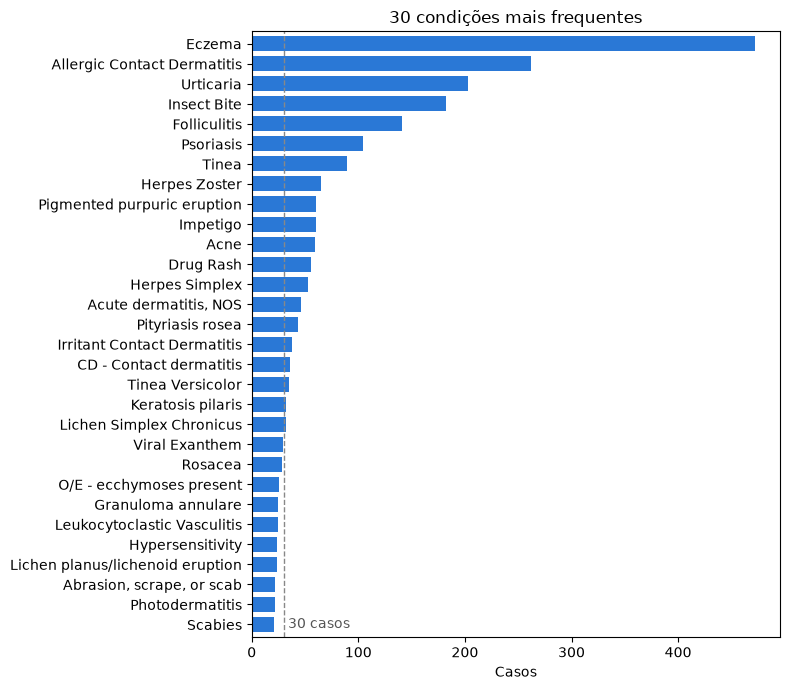

In [26]:
top = pesos[tem].map(lambda d: max(d, key=d.get))
vc = top.value_counts()
print(f"{len(vc)} condições como principal ({len(Counter(k for d in pesos for k in d))} com qualquer peso)")
print(f"Com pelo menos 30 casos: {(vc >= 30).sum()} | 10 a 29: {((vc >= 10) & (vc < 30)).sum()} | menos de 10: {(vc < 10).sum()}")

fig, ax = plt.subplots(figsize=(8, 7))
vc.head(30).iloc[::-1].plot.barh(ax=ax, color=BLUE, width=0.75)
ax.axvline(30, color="#888", linestyle="--", linewidth=1)
ax.text(34, 0, "30 casos", color="#555", va="center")
ax.grid(axis="y", visible=False)
ax.set(xlabel="Casos", ylabel="", title="30 condições mais frequentes")
plt.tight_layout(); plt.show()

### Tipo de pele, idade e sexo

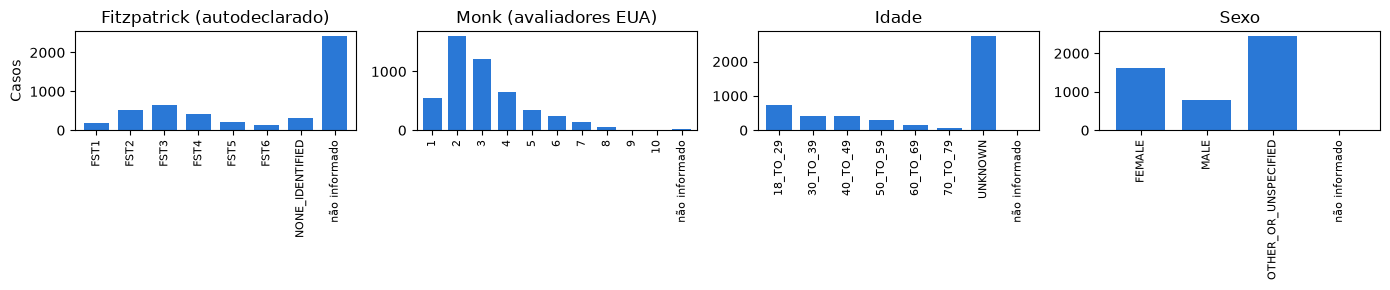

Sem Fitzpatrick: 50% | idade desconhecida: 57%


In [27]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
series = [("fitzpatrick_skin_type", "Fitzpatrick (autodeclarado)"), ("monk_skin_tone_label_us", "Monk (avaliadores EUA)"),
          ("age_group", "Idade"), ("sex_at_birth", "Sexo")]
for ax, (col, title) in zip(axes, series):
    s = scin_bruto[col].fillna("não informado").astype(str).str.replace("AGE_", "").str.replace(".0", "", regex=False)
    counts = s.value_counts().sort_index()
    if col == "monk_skin_tone_label_us":
        counts = counts.reindex(sorted(counts.index, key=lambda v: float(v) if v[0].isdigit() else 99))
    counts.plot.bar(ax=ax, color=BLUE, width=0.75)
    ax.grid(axis="x", visible=False)
    ax.set(title=title, xlabel="", ylabel="Casos" if ax is axes[0] else "")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print("Sem Fitzpatrick:", f"{scin_bruto['fitzpatrick_skin_type'].isna().mean():.0%}", "| idade desconhecida:", f"{(scin_bruto['age_group'] == 'AGE_UNKNOWN').mean():.0%}")

### Há queimaduras, feridas ou pintas?

Termos procurados em todas as condições citadas, inclusive as de menor peso. O grupo vem de `clean_scin.group_of`.

In [28]:
linhas = []
for d in pesos:
    for k, v in d.items():
        g = group_of(k)
        if g != "erupcao_alergia":
            linhas.append({"grupo": g, "condicao": k, "peso": v, "principal": k == max(d, key=d.get)})
t = pd.DataFrame(linhas)
resumo = t.groupby("grupo").agg(casos_citados=("condicao", "size"), casos_como_principal=("principal", "sum"), condicoes=("condicao", "nunique"))
display(resumo)
for g, s in t.groupby("grupo"):
    print(g, "->", s["condicao"].value_counts().head(8).to_dict())

,casos_citados,casos_como_principal,condicoes
grupo,,,
ferida,82,40,18
pinta,66,22,6
queimadura,32,7,9


ferida -> {'Abrasion, scrape, or scab': 46, 'Superficial wound of body region': 9, 'Animal bite - wound': 7, 'Foot ulcer': 2, 'Abrasion of wrist': 2, 'Skin ulcer': 2, 'Venous Stasis Ulcer': 2, 'Traumatic ulcer': 2}
pinta -> {'Actinic Keratosis': 20, 'Basal Cell Carcinoma': 19, 'Melanocytic Nevus': 12, 'Melanoma': 7, 'Atypical Nevus': 5, 'Lentigo': 3}
queimadura -> {'Burn of skin': 16, 'Sunburn': 6, 'Burn erythema of back of hand': 3, 'Burn erythema of lower leg': 2, 'Contact burn of skin': 1, 'Burn of forearm': 1, 'post-sunburn peeling/superficial desquamation': 1, 'Burn erythema of abdominal wall': 1}


## Etapa 2: limpeza dos dados

Cada imagem passa por uma sequência de filtros, e a tabela guarda o motivo de cada remoção. Tudo é reproduzível; a extração e os hashes ficam em cache, então rodar de novo leva poucos minutos.

**Limiares escolhidos**
- `MIN_SIDE`: lado menor de pelo menos 224 px, o tamanho de entrada da rede.
- `MIN_CONFIDENCE = 1,5`: remove os casos em que os dermatologistas estavam, em média, quase no mínimo de confiança (escala de 1 a 5).
- `MIN_CASES = 30`: condições com menos casos vão para `outras_condicoes`.
- **Quase-duplicatas**: pHash com distância até 12 gera candidatas, e a correlação dos pixels ≥ 0,98 confirma. Na revisão manual de pares, só o pHash marcava como iguais fotos de pessoas diferentes (com distância 4 ou 6), porque fotos de pele têm pouco detalhe.

In [29]:
MIN_SIDE = 224
NEAR_DUP_MAX = 12         # distância de Hamming máxima no pHash para ser candidata
NEAR_DUP_CORR = 0.98      # correlação mínima dos pixels (cinza, 64x64) para confirmar
MIN_CONFIDENCE = 1.5      # confiança média mínima dos dermatologistas (escala de 1 a 5)
MIN_CASES = 30            # classes com menos casos viram "outras_condicoes"
OTHER = "outras_condicoes"

# rótulos que os dermatologistas usam como sinônimos: os pesos são somados
SYNONYMS = {
    "Allergic Contact Dermatitis": "Contact Dermatitis",
    "Irritant Contact Dermatitis": "Contact Dermatitis",
    "CD - Contact dermatitis": "Contact Dermatitis",
    "Acute dermatitis, NOS": "Dermatitis, NOS",
    "Chronic dermatitis, NOS": "Dermatitis, NOS",
    "Acute and chronic dermatitis": "Dermatitis, NOS",
}
IMAGE_COLS = [f"image_{i}_path" for i in (1, 2, 3)]
GRADABLE_COLS = [f"dermatologist_gradable_for_skin_condition_{i}" for i in (1, 2, 3)]
META_COLS = ["case_id", "age_group", "sex_at_birth", "fitzpatrick_skin_type", "related_category",
             "condition_duration", "monk_skin_tone_label_us", "monk_skin_tone_label_india",
             "dermatologist_fitzpatrick_skin_type_label_1", "dermatologist_skin_condition_confidence",
             "weighted_skin_condition_label", *GRADABLE_COLS]

### Extração das imagens dos parquets

Cada imagem vira um JPEG em `~/datasets/scin/images/`. O hash MD5 é do arquivo PNG original.

In [30]:
def phash_hex(img) -> str:
    return str(imagehash.phash(img))


def to_uint64(hashes) -> np.ndarray:
    return np.array([int(h, 16) for h in hashes], dtype=np.uint64)


def read_ids(path: Path) -> pd.DataFrame:
    return pd.read_csv(path, dtype={"case_id": str, "image_id": str}, low_memory=False)


def extract_one(item, images_dir: Path) -> dict:
    """Grava o JPEG de uma imagem do parquet e devolve seus hashes (os bytes são o PNG original)."""
    case_id, num, shot, cell = item
    image_id = Path(cell["path"]).stem
    row = {"case_id": case_id, "image_id": image_id, "image_num": num, "shot_type": shot,
           "md5": hashlib.md5(cell["bytes"]).hexdigest(), "corrompida": False}
    try:
        img = Image.open(io.BytesIO(cell["bytes"]))
        img.load()
        img = img.convert("RGB")
    except (UnidentifiedImageError, OSError, ValueError):
        return {**row, "corrompida": True}
    dst = images_dir / f"{image_id}.jpg"
    if not dst.exists():
        tmp = dst.with_suffix(".tmp")
        img.save(tmp, "JPEG", quality=95)
        os.replace(tmp, dst)
    return {**row, "largura": img.width, "altura": img.height,
            "phash": phash_hex(img), "phash_espelho": phash_hex(ImageOps.mirror(img))}


def extrair_scin(raw_dir: Path, out_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Extrai as imagens de todos os parquets. Devolve (imagens, casos) e guarda em cache."""
    images_dir = out_dir / "images"
    images_dir.mkdir(parents=True, exist_ok=True)
    img_cache, case_cache = out_dir / "_imagens_brutas.csv", out_dir / "_casos_brutos.csv"
    if img_cache.exists() and case_cache.exists():
        return read_ids(img_cache), read_ids(case_cache)
    files = sorted(raw_dir.glob("*.parquet"))
    if not files:
        sys.exit(f"Nenhum parquet em {raw_dir}")
    columns = META_COLS + IMAGE_COLS + [f"image_{i}_shot_type" for i in (1, 2, 3)]
    rows, cases = [], []
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        for n, f in enumerate(files, 1):
            for batch in pq.ParquetFile(f).iter_batches(batch_size=16, columns=columns):
                items = []
                for rec in batch.to_pylist():
                    cases.append({k: rec[k] for k in META_COLS})
                    items += [(rec["case_id"], i, rec[f"image_{i}_shot_type"], rec[f"image_{i}_path"])
                              for i in (1, 2, 3) if rec[f"image_{i}_path"] and rec[f"image_{i}_path"]["bytes"]]
                rows += list(pool.map(lambda it: extract_one(it, images_dir), items))
            print(f"[{n}/{len(files)}] {f.name}: {len(rows)} imagens", flush=True)
    pd.DataFrame(rows).to_csv(img_cache, index=False)
    pd.DataFrame(cases).to_csv(case_cache, index=False)
    return read_ids(img_cache), read_ids(case_cache)

### Duplicatas

Exatas por MD5 e quase-duplicatas por pHash + correlação, inclusive espelhadas. A checagem entre bases compara cada imagem do SCIN com as 33.568 imagens das bases de pintas, para não haver vazamento entre treino e teste.

In [31]:
def gray(path, mirror=False) -> np.ndarray:
    img = Image.open(path).convert("L").resize((64, 64))
    return np.asarray(ImageOps.mirror(img) if mirror else img, dtype=np.float32).ravel()


def confirmed(path_a, path_b, mirror: bool) -> bool:
    a, b = gray(path_a), gray(path_b, mirror)
    return a.std() > 0 and b.std() > 0 and np.corrcoef(a, b)[0, 1] >= NEAR_DUP_CORR


def near_duplicates(images: pd.DataFrame, images_dir: Path) -> set:
    """Índices a remover: de cada par confirmado, fica a primeira imagem da tabela."""
    h, flip = to_uint64(images["phash"]), to_uint64(images["phash_espelho"])
    ids, index = images["image_id"].values, images.index.values
    path = lambda k: images_dir / f"{ids[k]}.jpg"
    drop = set()
    for i in range(len(h) - 1):
        if index[i] in drop:
            continue
        direct = np.bitwise_count(h[i + 1:] ^ h[i])
        mirrored = np.bitwise_count(h[i + 1:] ^ flip[i])
        for off in np.where(np.minimum(direct, mirrored) <= NEAR_DUP_MAX)[0]:
            j = i + 1 + off
            if index[j] not in drop and confirmed(path(i), path(j), bool(mirrored[off] < direct[off])):
                drop.add(index[j])
    return drop


def lesion_phashes(out_dir: Path) -> pd.DataFrame:
    """pHash das imagens das bases de pintas (com cache: são 33 mil arquivos)."""
    cache = out_dir / "_phash_pintas.csv"
    if cache.exists():
        return pd.read_csv(cache)

    def one(path):
        img = Image.open(path)
        img.draft("RGB", (128, 128))  # decodifica o JPEG em escala menor, bem mais rápido
        return phash_hex(img.convert("RGB"))

    df = load_labels()[["image_path"]].copy()
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        df["phash"] = list(pool.map(one, df["image_path"]))
    df.to_csv(cache, index=False)
    return df


def cross_duplicates(images: pd.DataFrame, images_dir: Path, out_dir: Path) -> set:
    """Imagens do SCIN que também aparecem nas bases de pintas (arquivo idêntico ou quase-duplicata)."""
    lesions = lesion_phashes(out_dir)
    md5_file = DEFAULT_DIR.parent / "kaggle" / "lesoes-pele-meta" / "md5.csv"
    known = set(pd.read_csv(md5_file)["md5"]) if md5_file.exists() else set()
    target = to_uint64(lesions["phash"])
    paths = lesions["image_path"].values
    drop = set(images.index[images["md5"].isin(known)])
    h, flip = to_uint64(images["phash"]), to_uint64(images["phash_espelho"])
    for k, (idx, image_id) in enumerate(zip(images.index, images["image_id"])):
        direct = np.bitwise_count(target ^ h[k])
        mirrored = np.bitwise_count(target ^ flip[k])
        for j in np.where(np.minimum(direct, mirrored) <= NEAR_DUP_MAX)[0]:
            if idx not in drop and confirmed(images_dir / f"{image_id}.jpg", paths[j], bool(mirrored[j] < direct[j])):
                drop.add(idx)
    return drop

### Rótulos

A condição principal é a de maior peso; nos empates, a mais frequente na base. A coluna `rotulos_suaves` guarda todos os pesos.

In [32]:
def parse_labels(cases: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por caso: rótulo principal, rótulos suaves, confiança, avaliabilidade e grupo."""

    def merge(d):
        out = {}
        for k, v in d.items():
            name = SYNONYMS.get(k, k)
            out[name] = out.get(name, 0) + v
        return out

    weights = cases["weighted_skin_condition_label"].map(ast.literal_eval).map(merge)
    support = {}  # peso total de cada condição, para desempatar pela mais frequente
    for d in weights:
        for k, v in d.items():
            support[k] = support.get(k, 0) + v

    def top(d):
        return min(d, key=lambda k: (-round(d[k], 6), -support[k], k)) if d else None

    conf = cases["dermatologist_skin_condition_confidence"].map(ast.literal_eval)
    votes = cases[GRADABLE_COLS].astype("string")
    no = votes.apply(lambda c: c.str.startswith("NO_", na=False)).sum(axis=1)
    yes = votes.apply(lambda c: c.str.contains("YES", na=False)).sum(axis=1)
    out = cases.drop(columns=["weighted_skin_condition_label", "dermatologist_skin_condition_confidence", *GRADABLE_COLS])
    out["condicao"] = weights.map(top)
    out["peso_condicao"] = weights.map(lambda d: max(d.values()) if d else np.nan)
    out["rotulos_suaves"] = weights.map(lambda d: json.dumps({k: round(v, 4) for k, v in d.items()}, ensure_ascii=False))
    out["confianca_media"] = conf.map(lambda c: float(np.mean(c)) if c else np.nan)
    out["n_dermatologistas"] = conf.map(len)
    out["nao_avaliavel"] = no > yes
    out["grupo"] = out["condicao"].map(group_of)
    return out

### Rodando a limpeza

In [33]:
def limpar_scin(raw_dir: Path = SCIN_RAW_DIR, out_dir: Path = SCIN_DIR) -> pd.DataFrame:
    images, cases = extrair_scin(raw_dir, out_dir)
    images_dir = out_dir / "images"
    table = images.merge(parse_labels(cases), on="case_id", how="left", validate="m:1")
    # entre imagens repetidas, fica a de um caso com rótulo
    table["_tem_rotulo"] = table["condicao"].notna()
    table = table.sort_values(["_tem_rotulo", "case_id", "image_num"], ascending=[False, True, True],
                              kind="stable").reset_index(drop=True)
    table["motivo"] = pd.Series(pd.NA, index=table.index, dtype="string")
    report = [{"etapa": "entrada", "imagens": len(table), "casos": table["case_id"].nunique()}]

    def apply(reason, mask):
        table.loc[table["motivo"].isna() & mask, "motivo"] = reason
        alive = table[table["motivo"].isna()]
        report.append({"etapa": reason, "imagens": len(alive), "casos": alive["case_id"].nunique()})

    apply("corrompida", table["corrompida"].astype(bool))
    apply("muito_pequena", table[["largura", "altura"]].min(axis=1) < MIN_SIDE)
    alive = table[table["motivo"].isna()]
    apply("duplicata_exata", table.index.isin(alive.index[alive.duplicated("md5")]))
    apply("quase_duplicata", table.index.isin(near_duplicates(table[table["motivo"].isna()], images_dir)))
    apply("duplicata_entre_bases", table.index.isin(cross_duplicates(table[table["motivo"].isna()], images_dir, out_dir)))
    apply("nao_avaliavel", table["nao_avaliavel"].astype(bool))
    apply("sem_rotulo", table["condicao"].isna())
    apply("baixa_confianca", table["confianca_media"] < MIN_CONFIDENCE)

    kept = table[table["motivo"].isna()].drop(columns=["_tem_rotulo", "corrompida", "motivo"]).copy()
    n_cases = kept.drop_duplicates("case_id")["condicao"].value_counts()
    common = set(n_cases[n_cases >= MIN_CASES].index)
    kept["classe"] = kept["condicao"].where(kept["condicao"].isin(common), OTHER)
    kept["image_path"] = "images/" + kept["image_id"] + ".jpg"

    table.drop(columns="_tem_rotulo").to_csv(out_dir / "imagens.csv", index=False)
    kept.to_csv(out_dir / "meta.csv", index=False)
    by_case = kept.drop_duplicates("case_id")
    summary = {
        "etapas": report,
        "limiares": {"MIN_SIDE": MIN_SIDE, "NEAR_DUP_MAX": NEAR_DUP_MAX, "NEAR_DUP_CORR": NEAR_DUP_CORR,
                     "MIN_CONFIDENCE": MIN_CONFIDENCE, "MIN_CASES": MIN_CASES},
        "classes_mantidas": by_case[by_case["classe"] != OTHER]["classe"].value_counts().to_dict(),
        "casos_em_outras": int((by_case["classe"] == OTHER).sum()),
        "condicoes_em_outras": int(n_cases.size - len(common)),
        "casos_por_grupo": by_case["grupo"].value_counts().to_dict(),
    }
    (out_dir / "limpeza.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    return kept

In [34]:
scin_limpo = limpar_scin()
print(f"{len(scin_limpo)} imagens de {scin_limpo['case_id'].nunique()} casos")

5434 imagens de 2581 casos


In [35]:
resumo = json.loads((SCIN_DIR / "limpeza.json").read_text(encoding="utf-8"))
etapas = pd.DataFrame(resumo["etapas"])
etapas["imagens_removidas"] = -etapas["imagens"].diff().fillna(0).astype(int)
etapas

,etapa,imagens,casos,imagens_removidas
0,entrada,9998,4839,0
1,corrompida,9998,4839,0
2,muito_pequena,9972,4838,26
3,duplicata_exata,9947,4820,25
4,quase_duplicata,9932,4818,15
5,duplicata_entre_bases,9932,4818,0
6,nao_avaliavel,6150,2942,3782
7,sem_rotulo,5975,2847,175
8,baixa_confianca,5434,2581,541


### Exemplos das classes principais

Só fotos em close, de adultos e sem tronco, nádegas ou região genital, por se tratar de fotos de pessoas reais. Os rótulos fazem sentido visualmente: as bolhas agrupadas do herpes e as placas da psoríase, por exemplo.

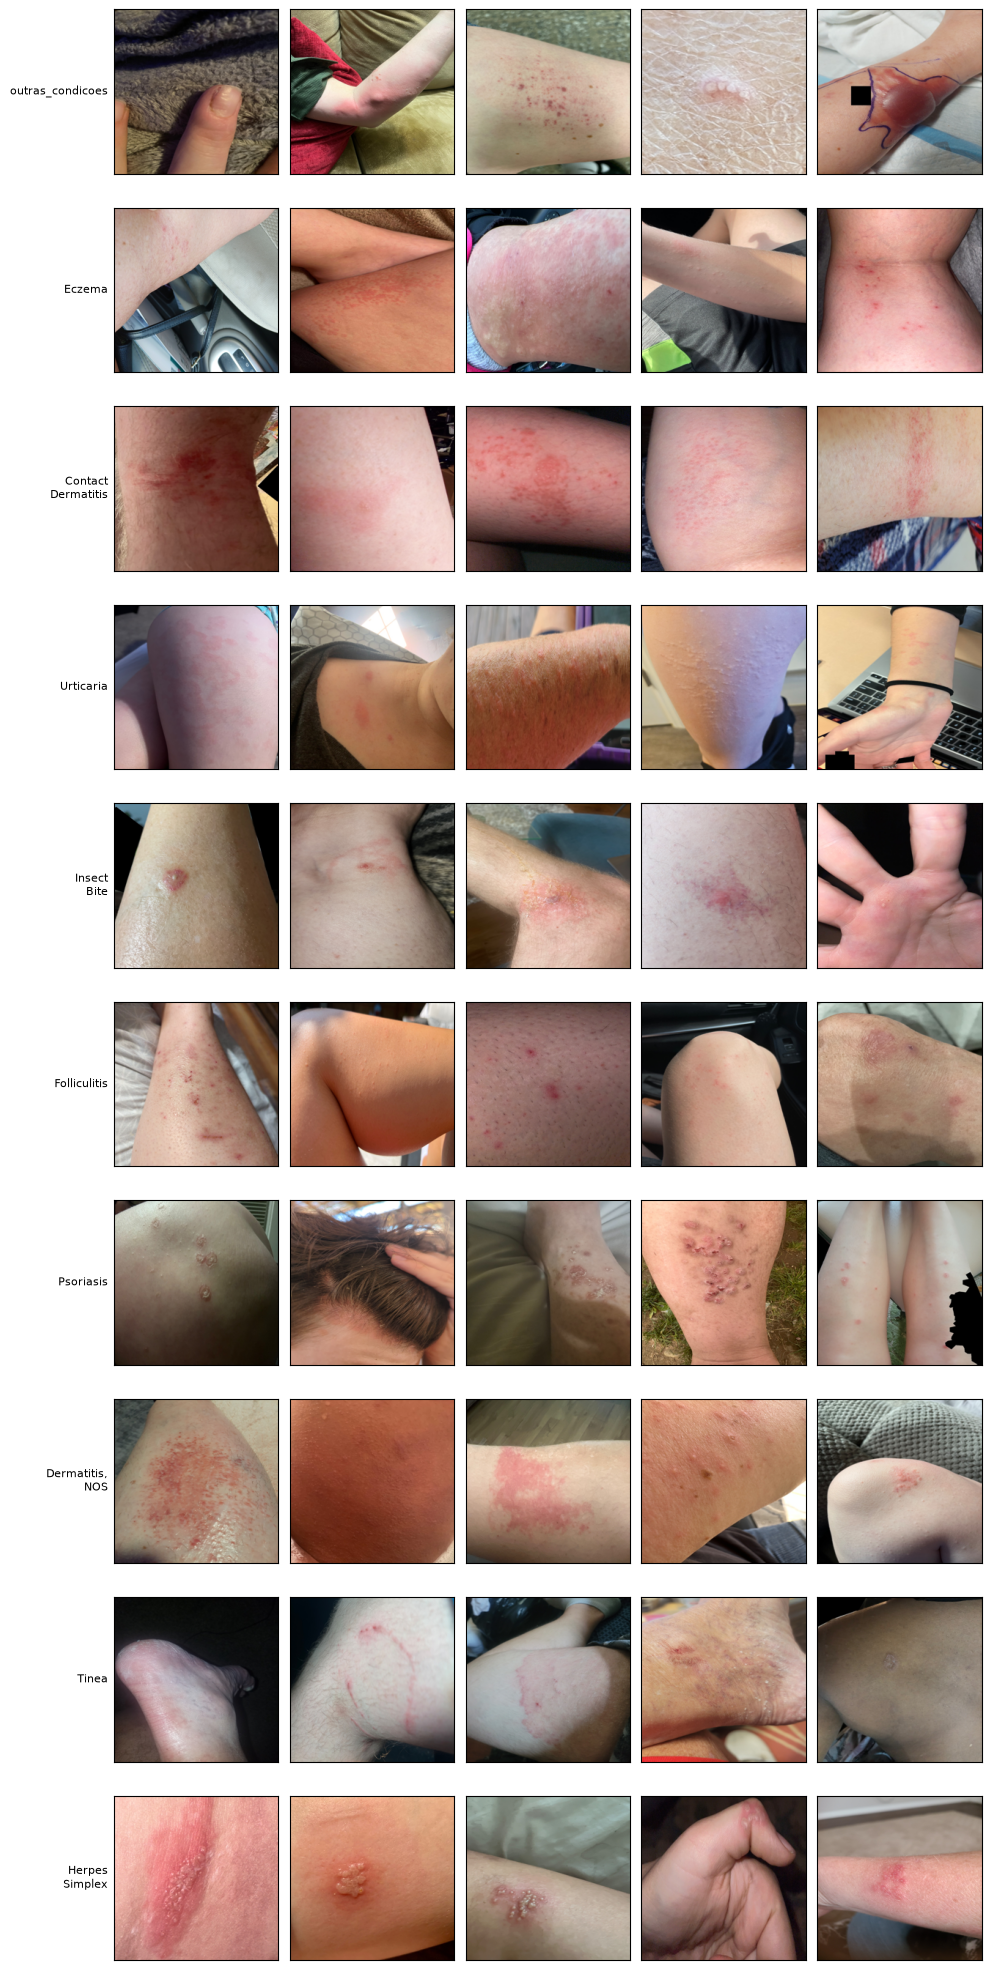

In [36]:
meta = pd.read_csv(SCIN_DIR / "meta.csv", dtype={"case_id": str, "image_id": str}, low_memory=False)
evitar = ["body_parts_genitalia_or_groin", "body_parts_buttocks", "body_parts_torso_front", "body_parts_torso_back"]
sensivel = set(scin_bruto.loc[(scin_bruto[evitar] == "YES").any(axis=1), "case_id"])
adultos = meta["age_group"].fillna("AGE_UNKNOWN") != "AGE_UNKNOWN"  # só idade declarada (18 anos ou mais)
amostra = meta[(~meta["case_id"].isin(sensivel)) & (meta["shot_type"] == "CLOSE_UP") & adultos]
classes = meta.drop_duplicates("case_id")["classe"].value_counts().index[:10]
N = 5
fig, axes = plt.subplots(len(classes), N, figsize=(2 * N, 2 * len(classes)))
for row, c in zip(axes, classes):
    imgs = amostra[amostra["classe"] == c].drop_duplicates("case_id").sample(N, random_state=42)
    for ax, (_, r) in zip(row, imgs.iterrows()):
        ax.imshow(Image.open(SCIN_DIR / r["image_path"]).convert("RGB").resize((224, 224)))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    row[0].set_ylabel(c.replace(" ", "\n"), fontsize=8, rotation=0, ha="right", va="center")
plt.tight_layout(); plt.show()

## Etapa 3: treino, validação e teste

Divisão 70/15/15 por `case_id` (as fotos de um caso são da mesma lesão), estratificada pela classe e com semente fixa. O resultado fica versionado em `splits/scin_v1.csv`. O código confere que nenhum caso ou imagem repetida aparece em dois conjuntos. O teste é separado aqui, antes de qualquer decisão de modelagem, e só entra na avaliação final.

In [37]:
N_FOLDS = 20    # 3 dobras (15%) para o teste, 3 para a validação e 14 (70%) para o treino


def make_splits(meta: pd.DataFrame) -> pd.DataFrame:
    # grupos raros entram como estrato próprio, para não caírem todos num conjunto só
    strata = meta["classe"].where(meta["grupo"] == "erupcao_alergia", meta["grupo"])
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
    split = pd.Series("train", index=meta.index)
    for fold, (_, idx) in enumerate(folds.split(meta, strata, groups=meta["case_id"])):
        if fold < 3:
            split.iloc[idx] = "test"
        elif fold < 6:
            split.iloc[idx] = "val"
    return meta.assign(split=split)


def verify(data: pd.DataFrame, images_dir: Path) -> None:
    """Interrompe com erro se algum caso ou imagem repetida estiver em mais de um conjunto."""
    assert data["image_id"].is_unique, "image_id repetido"
    per_case = data.groupby("case_id")["split"].nunique()
    assert (per_case == 1).all(), f"{(per_case > 1).sum()} casos em mais de um conjunto"
    per_md5 = data.groupby("md5")["split"].nunique()
    assert (per_md5 == 1).all(), f"{(per_md5 > 1).sum()} arquivos idênticos em mais de um conjunto"
    near = near_duplicates(data.reset_index(drop=True), images_dir)
    assert not near, f"{len(near)} quase-duplicatas restantes (r >= {NEAR_DUP_CORR})"
    print(f"Verificado: {data['case_id'].nunique()} casos em um único conjunto; sem imagens repetidas entre conjuntos")

In [38]:
scin_split = make_splits(read_ids(SCIN_DIR / "meta.csv"))
verify(scin_split, SCIN_DIR / "images")
SPLITS.mkdir(exist_ok=True)
scin_split[["image_id", "case_id", "classe", "grupo", "split"]].sort_values("image_id").to_csv(SCIN_SPLITS, index=False)
por_caso = scin_split.drop_duplicates("case_id")
print(scin_split["split"].value_counts(normalize=True).round(3).to_dict(), "(imagens)")
display(pd.crosstab(por_caso["grupo"], por_caso["split"], margins=True))
pd.crosstab(por_caso["classe"], por_caso["split"], margins=True)

C:\Users\felip\AppData\Roaming\Python\Python314\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 8 members, which is less than n_splits=20.
  warnings.warn(


Verificado: 2581 casos em um único conjunto; sem imagens repetidas entre conjuntos
{'train': 0.7, 'val': 0.15, 'test': 0.15} (imagens)


split,test,train,val,All
grupo,,,,
erupcao_alergia,380,1770,380,2530
ferida,4,21,5,30
pinta,2,13,2,17
queimadura,1,3,0,4
All,387,1807,387,2581


split,test,train,val,All
classe,,,,
Acne,8,35,7,50
Contact Dermatitis,66,309,67,442
"Dermatitis, NOS",7,48,10,65
Drug Rash,6,30,6,42
Eczema,75,344,76,495
Folliculitis,17,79,18,114
Herpes Simplex,9,41,8,58
Herpes Zoster,6,33,6,45
Insect Bite,24,116,24,164


## PAD-UFES-20: fotos de celular de lesões de pele

O SCIN quase não tem pintas (17 casos depois da limpeza), e as bases do modelo de pintas são dermatoscópicas. Para ter pintas em foto de celular, baixamos o **PAD-UFES-20** (Mendeley Data, licença CC BY): 2.298 fotos de 1.373 pacientes, de lesões com diagnóstico ACK, BCC, MEL, NEV, SCC ou SEK. A divisão é por paciente. Se a base já estiver preparada, as células abaixo não baixam nada.

In [39]:
PAD_API = "https://data.mendeley.com/public-api/datasets/zr7vgbcyr2"


def baixar_pad():
    """Baixa o PAD-UFES-20 e confere o SHA-256 de cada arquivo."""
    def get(path):
        return json.load(urllib.request.urlopen(urllib.request.Request(PAD_API + path, headers={"User-Agent": "research-download"}), timeout=60))

    PAD_RAW_DIR.mkdir(parents=True, exist_ok=True)
    files = get("/files?folder_id=root&version=1")
    for folder in get("/folders/1"):
        files += get(f"/files?folder_id={folder['id']}&version=1")
    for f in files:
        info, dst = f["content_details"], PAD_RAW_DIR / f["filename"]
        if not (dst.exists() and dst.stat().st_size == info["size"]):
            print("Baixando", f["filename"], flush=True)
            with urllib.request.urlopen(urllib.request.Request(info["download_url"], headers={"User-Agent": "research-download"}), timeout=120) as r, open(dst, "wb") as out:
                while chunk := r.read(1 << 20):
                    out.write(chunk)
        h = hashlib.sha256()
        with open(dst, "rb") as source:
            while chunk := source.read(1 << 20):
                h.update(chunk)
        assert h.hexdigest() == info["sha256_hash"], f"{f['filename']} corrompido"

In [40]:
def extrair_pad(raw: Path, out: Path) -> pd.DataFrame:
    images_dir = out / "images"
    images_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for part in sorted(raw.glob("imgs_part_*.zip")):
        with zipfile.ZipFile(part) as z:
            for name in z.namelist():
                if not name.lower().endswith(".png"):
                    continue
                data = z.read(name)
                img = Image.open(io.BytesIO(data)).convert("RGB")
                image_id = Path(name).stem  # só o nome do arquivo, nunca o caminho dentro do zip
                img.save(images_dir / f"{image_id}.jpg", "JPEG", quality=95)
                rows.append({"image_id": image_id, "md5": hashlib.md5(data).hexdigest(), "phash": phash_hex(img),
                             "phash_espelho": phash_hex(ImageOps.mirror(img))})
    return pd.DataFrame(rows)


def duplicates_of_scin(images: pd.DataFrame, images_dir: Path) -> set:
    scin = read_ids(SCIN_DIR / "imagens.csv")
    scin = scin[scin["motivo"].isna()]
    target, paths = to_uint64(scin["phash"]), [SCIN_DIR / "images" / f"{i}.jpg" for i in scin["image_id"]]
    drop = set(images.index[images["md5"].isin(set(scin["md5"]))])
    h, flip = to_uint64(images["phash"]), to_uint64(images["phash_espelho"])
    for k, (idx, image_id) in enumerate(zip(images.index, images["image_id"])):
        direct, mirrored = np.bitwise_count(target ^ h[k]), np.bitwise_count(target ^ flip[k])
        for j in np.where(np.minimum(direct, mirrored) <= NEAR_DUP_MAX)[0]:
            if idx not in drop and confirmed(images_dir / f"{image_id}.jpg", paths[j], bool(mirrored[j] < direct[j])):
                drop.add(idx)
    return drop


def preparar_pad(raw=PAD_RAW_DIR, out=PAD_DIR):
    """Extrai as imagens, remove duplicatas e separa por paciente."""
    images = extrair_pad(raw, out)
    images = images.drop_duplicates("md5")
    meta = pd.read_csv(raw / "metadata.csv")
    meta["image_id"] = meta["img_id"].str.replace(".png", "", regex=False)
    table = images.merge(meta[["image_id", "patient_id", "lesion_id", "diagnostic", "region", "fitspatrick", "age", "biopsed"]],
                         on="image_id", validate="1:1")
    images_dir = out / "images"
    other_lesions = cross_duplicates(table, images_dir, SCIN_DIR)
    scin = duplicates_of_scin(table, images_dir)
    keep = ~table.index.isin(other_lesions | scin)
    table = table[keep].reset_index(drop=True)
    table["image_path"] = "images/" + table["image_id"] + ".jpg"

    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
    split = pd.Series("train", index=table.index)
    for fold, (_, idx) in enumerate(folds.split(table, table["diagnostic"], groups=table["patient_id"])):
        if fold < 3:
            split.iloc[idx] = "test"
        elif fold < 6:
            split.iloc[idx] = "val"
    table["split"] = split
    per_patient = table.groupby("patient_id")["split"].nunique()
    assert (per_patient == 1).all(), "paciente em mais de um conjunto"

    PAD_SPLITS.parent.mkdir(exist_ok=True)
    table[["image_id", "patient_id", "diagnostic", "split"]].sort_values("image_id").to_csv(PAD_SPLITS, index=False)
    table.drop(columns="split").to_csv(out / "meta.csv", index=False)  # o split fica só em splits/pad_v1.csv
    summary = {"imagens": len(table), "pacientes": int(table["patient_id"].nunique()),
               "duplicatas_com_pintas": len(other_lesions), "duplicatas_com_scin": len(scin)}
    (out / "preparo.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print(summary)
    print(pd.crosstab(table["diagnostic"], table["split"], margins=True).to_string())

In [41]:
if not (PAD_DIR / "meta.csv").exists():
    baixar_pad()
    preparar_pad()
print(json.loads((PAD_DIR / "preparo.json").read_text()))
pd.crosstab(pd.read_csv(PAD_SPLITS)["diagnostic"], pd.read_csv(PAD_SPLITS)["split"], margins=True)

{'imagens': 2283, 'pacientes': 1373, 'duplicatas_com_pintas': 0, 'duplicatas_com_scin': 0}


split,test,train,val,All
diagnostic,,,,
ACK,108,507,109,724
BCC,126,587,126,839
MEL,8,38,6,52
NEV,38,168,38,244
SCC,30,132,28,190
SEK,34,164,36,234
All,344,1596,343,2283


## Etapa 4: arquitetura e treino

```
imagem -> detector de tipo de foto -+- dermatoscopia -> modelo de pintas
                                    |
                                    +- foto de celular -> roteador -+- pinta -> modelo de pintas + orientação de avaliação médica
                                                                    +- erupção/alergia -> especialista (17 classes)
                                                                    +- baixa confiança -> "não foi possível identificar"
```

**Por que dois passos.** A proposta inicial era um único roteador juntando as bases de pintas e o SCIN. Mas as bases de pintas são dermatoscópicas e o SCIN é de celular, e o roteador aprenderia o tipo de foto, não o tipo de lesão. Assim, primeiro um detector separa dermatoscopia de celular, e o roteador compara só fotos de celular (PAD-UFES-20 × SCIN).

**Pinta em foto de celular também passa pelo modelo de pintas**, que foi adaptado para isso e sugere as classes mais prováveis. A urgência, porém, nunca cai para "cuidados em casa": foto de celular não permite descartar um câncer (o modelo ainda perde 3,4% dos malignos no teste de celular), então a saída é sempre uma orientação de avaliação médica; a suspeita só muda o texto.

**CNN como roteador, e não regras sobre a imagem**: regras manuais não separam esses grupos pela aparência. As regras entram depois da classificação, para definir a urgência (Etapa 5).

**Queimaduras e feridas ficam desativadas.** Só há 4 casos de queimadura e 30 de ferida depois da limpeza, o que não basta para treinar nem para avaliar. Os grupos estão previstos em `orientacoes.yaml`, com `ativo: false`, à espera de bases específicas.

**Rótulo único × rótulos suaves.** O especialista é treinado das duas formas, e a validação decide pelo F1 macro.

In [42]:
TRIAGEM_IMG = 224
TRIAGEM_BATCH = 32
TRIAGEM_CACHE_LADO = 256
TRIAGEM_HEAD_EPOCHS = 2
TRIAGEM_EPOCHS = 12
TRIAGEM_PATIENCE = 4
TRIAGEM_LR = 3e-4
TRIAGEM_WD = 0.02
N_DERMOSCOPY = 4000          # imagens dermatoscópicas no treino do detector de modalidade
ABSTAIN_PCT = {"roteador": 5, "especialista_erupcao": 10}  # % da validação abaixo do limiar de confiança
ROUTER_CLASSES = ["erupcao_alergia", "pinta"]
MODALITY_CLASSES = ["celular", "dermatoscopia"]
TRIAGEM_CACHE = DEFAULT_DIR.parent / "triagem_cache_256"

### Dados de cada rede

As imagens são reduzidas a lado menor de 256 px, sem mexer nas cores. Aqui não usamos Shades of Gray: a cor ajuda a sugerir a condição, e em foto de celular não há dermatoscópio para compensar. Os casos de pinta do SCIN ficam **fora do treino do roteador**, como teste externo.

In [43]:
def read_scin() -> pd.DataFrame:
    """Imagens do SCIN limpas, com o split e os rótulos suaves."""
    meta = pd.read_csv(SCIN_DIR / "meta.csv", dtype={"case_id": str, "image_id": str}, low_memory=False)
    splits = pd.read_csv(SCIN_SPLITS, dtype={"case_id": str, "image_id": str})[["image_id", "split"]]
    df = meta.merge(splits, on="image_id", validate="1:1")
    df["path"] = df["image_path"].map(lambda p: str(SCIN_DIR / p))
    return df


def read_pad() -> pd.DataFrame:
    df = pd.read_csv(PAD_DIR / "meta.csv", dtype={"patient_id": str, "lesion_id": str, "image_id": str})
    splits = pd.read_csv(PAD_SPLITS, dtype={"image_id": str})[["image_id", "split"]]
    df = df.merge(splits, on="image_id", validate="1:1")
    df["path"] = df["image_path"].map(lambda p: str(PAD_DIR / p))
    return df


def read_dermoscopy() -> pd.DataFrame:
    df = load_labels()
    df = df[df["split"].isin(["train", "val", "test"])]
    train = df[df["split"] == "train"].sample(N_DERMOSCOPY, random_state=SEED)
    df = pd.concat([train, df[df["split"] != "train"]], ignore_index=True)
    return df.assign(path=df["image_path"].astype(str))


def cached(paths) -> list:
    """Reduz as imagens a lado menor de 256 px, sem alterar as cores, uma única vez."""
    TRIAGEM_CACHE.mkdir(parents=True, exist_ok=True)

    def one(src):
        src = Path(src)
        dst = TRIAGEM_CACHE / f"{src.stem}.jpg"
        if not dst.exists():
            img = Image.open(src).convert("RGB")
            scale = TRIAGEM_CACHE_LADO / min(img.size)
            img = img.resize((round(img.width * scale), round(img.height * scale)), Image.BICUBIC)
            tmp = dst.with_suffix(".tmp")
            img.save(tmp, "JPEG", quality=95)
            os.replace(tmp, dst)
        return str(dst)

    with ThreadPoolExecutor(os.cpu_count()) as pool:
        return list(pool.map(one, paths))


def modality_data() -> pd.DataFrame:
    scin, pad, derm = read_scin(), read_pad(), read_dermoscopy()
    rows = [scin.assign(modalidade="celular", origem="SCIN"), pad.assign(modalidade="celular", origem="PAD"),
            derm.assign(modalidade="dermatoscopia", origem="ISIC")]
    data = pd.concat([r[["path", "split", "modalidade", "origem"]] for r in rows], ignore_index=True)
    return data.assign(cache=cached(data["path"]))


def router_data() -> pd.DataFrame:
    """Fotos de celular: PAD-UFES (pinta) + SCIN erupção. Os casos de pinta do SCIN ficam de fora, como teste externo."""
    scin = read_scin()
    scin = scin[scin["grupo"] == "erupcao_alergia"]
    data = pd.concat([scin.assign(rota="erupcao_alergia", origem="SCIN")[["path", "split", "rota", "origem"]],
                      read_pad().assign(rota="pinta", origem="PAD")[["path", "split", "rota", "origem"]]],
                     ignore_index=True)
    return data.assign(cache=cached(data["path"]))


def specialist_data():
    scin = read_scin()
    scin = scin[scin["grupo"] == "erupcao_alergia"].reset_index(drop=True)
    classes = sorted(c for c in scin["classe"].unique() if c != OTHER) + [OTHER]
    index = {c: i for i, c in enumerate(classes)}

    def soft(text):
        t = np.zeros(len(classes), "float32")
        for condition, weight in json.loads(text).items():
            t[index.get(condition, index[OTHER])] += weight
        return t / t.sum()

    soft_targets = np.stack(scin["rotulos_suaves"].map(soft).values)
    hard = scin["classe"].map(index).values
    return scin.assign(cache=cached(scin["path"])), classes, hard, soft_targets

### Rede e treino

A mesma receita do modelo de pintas (EfficientNetV2-B0, 224 px, transfer learning em duas fases, AdamW com decaimento cosseno, BatchNormalization congeladas). Desbalanceamento: peso pela raiz do inverso da frequência. Data augmentation com variação de cor moderada, porque a cor é informação diagnóstica.

In [44]:
def aumentar_foto(img):
    """Recortes, espelhamentos e rotações; variação de cor moderada, porque a cor ajuda a sugerir a condição."""
    begin, crop, _ = tf.image.sample_distorted_bounding_box(
        tf.shape(img), bounding_boxes=tf.zeros([1, 0, 4]), min_object_covered=0.0,
        aspect_ratio_range=(3 / 4, 4 / 3), area_range=(0.5, 1.0), max_attempts=10,
        use_image_if_no_bounding_boxes=True)
    img = tf.image.resize(tf.slice(img, begin, crop), (TRIAGEM_IMG, TRIAGEM_IMG))
    img = tf.image.random_flip_left_right(img)
    img = tf.image.rot90(img, tf.random.uniform([], 0, 4, dtype=tf.int32))
    x = tf.image.random_brightness(img / 255.0, 0.1)
    x = tf.image.random_contrast(x, 0.9, 1.1)
    x = tf.image.random_saturation(x, 0.9, 1.1)
    return tf.clip_by_value(tf.image.random_hue(x, 0.01), 0.0, 1.0) * 255.0


def ds_triagem(paths, targets=None, weights=None, training=False):
    tensors = {"path": list(paths)}
    if targets is not None:
        tensors["y"] = np.asarray(targets, "float32")
    if weights is not None:
        tensors["w"] = np.asarray(weights, "float32")
    ds = tf.data.Dataset.from_tensor_slices(tensors)
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)

    def load(item):
        img = decode(item["path"])
        img = aumentar_foto(img) if training else center_crop(img, TRIAGEM_IMG)
        if "w" in item:
            return img, item["y"], item["w"]
        return (img, item["y"]) if "y" in item else img

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(TRIAGEM_BATCH, drop_remainder=training).prefetch(tf.data.AUTOTUNE)


def montar_rede(n_classes):
    base = applications.EfficientNetV2B0(include_top=False, weights="imagenet",
                                         input_shape=(TRIAGEM_IMG, TRIAGEM_IMG, 3), pooling="avg")
    image = keras.Input((TRIAGEM_IMG, TRIAGEM_IMG, 3), name="image")
    logits = layers.Dense(n_classes, name="logits")(layers.Dropout(0.3)(base(image)))
    return keras.Model(image, logits), base


class MetricasTriagem(callbacks.Callback):
    """Acurácia balanceada na validação, que escolhe o melhor checkpoint."""

    def __init__(self, ds, y):
        super().__init__()
        self.ds, self.y = ds, y

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.ds, verbose=0).argmax(1)
        logs["val_bal_acc"] = balanced_accuracy_score(self.y, pred)
        logs["val_f1_macro"] = f1_score(self.y, pred, average="macro")
        print(f"  época {epoch + 1}: val_bal_acc={logs['val_bal_acc']:.4f} val_f1_macro={logs['val_f1_macro']:.4f}", flush=True)


def pesos_classes(y, n_classes):
    """Peso pela raiz do inverso da frequência: compensa o desbalanceamento sem distorcer demais."""
    counts = np.bincount(y, minlength=n_classes).astype(float)
    w = np.sqrt(counts.sum() / np.maximum(counts, 1))
    return w / w[y].mean()


def treinar_rede(name, data, classes, targets, y=None, fine_tune=True):
    """Treina em duas fases. `targets`: matriz N x classes com a distribuição-alvo de cada imagem;
    `y`: rótulo único usado nos pesos e na validação (por padrão, o maior valor de `targets`)."""
    out = WORK_DIR / name
    out.mkdir(parents=True, exist_ok=True)
    y = targets.argmax(1) if y is None else y
    tr, va = (data["split"] == "train").values, (data["split"] == "val").values
    weights = pesos_classes(y[tr], len(classes))[y[tr]]
    train_ds = ds_triagem(data["cache"][tr], targets[tr], weights, training=True)
    val_ds = ds_triagem(data["cache"][va])
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)
    model, base = montar_rede(len(classes))

    head = out / "fase1.weights.h5"
    if head.exists():
        model.load_weights(head)
    else:
        base.trainable = False
        model.compile(optimizer=optimizers.AdamW(1e-3, weight_decay=TRIAGEM_WD), loss=loss)
        model.fit(train_ds, epochs=TRIAGEM_HEAD_EPOCHS, verbose=2, callbacks=[
            callbacks.BackupAndRestore(str(out / "backup_fase1")), MetricasTriagem(val_ds, y[va])])
        model.save_weights(head)
    ckpt = out / "melhor.keras"
    if not fine_tune:
        model.save(ckpt)
        return keras.models.load_model(ckpt, compile=False)

    per_epoch = int(train_ds.cardinality())
    base.trainable = True
    for layer in base.layers:  # como no modelo de pintas: BatchNormalization em modo de inferência
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    schedule = optimizers.schedules.CosineDecay(TRIAGEM_LR / 20, decay_steps=per_epoch * (TRIAGEM_EPOCHS - 1), alpha=0.01,
                                                warmup_target=TRIAGEM_LR, warmup_steps=per_epoch)
    opt = optimizers.AdamW(schedule, weight_decay=TRIAGEM_WD)
    opt.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])
    model.compile(optimizer=opt, loss=loss)
    hist = out / "historico.csv"
    best = pd.read_csv(hist)["val_bal_acc"].max() if hist.exists() and hist.stat().st_size else None
    model.fit(train_ds, epochs=TRIAGEM_EPOCHS, verbose=2, callbacks=[
        callbacks.BackupAndRestore(str(out / "backup_fase2")),
        MetricasTriagem(val_ds, y[va]),
        callbacks.ModelCheckpoint(str(ckpt), monitor="val_bal_acc", mode="max", save_best_only=True,
                                  initial_value_threshold=best),
        callbacks.EarlyStopping(monitor="val_bal_acc", mode="max", patience=TRIAGEM_PATIENCE),
        callbacks.CSVLogger(str(hist), append=True),
    ])
    return keras.models.load_model(ckpt, compile=False)

### Calibração e publicação dos modelos

A temperatura (*temperature scaling*) e o limiar de baixa confiança são ajustados **só na validação**.

In [45]:
def fit_temperature(logits, y):
    """Temperature scaling: a temperatura que minimiza a perda na validação."""
    def nll(t):
        p = scipy_softmax(logits / t, axis=1)
        return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()
    return float(minimize_scalar(nll, bounds=(0.05, 10), method="bounded").x)


def update_thresholds(name, entry):
    MODELS.mkdir(parents=True, exist_ok=True)
    current = json.loads(THRESHOLDS.read_text(encoding="utf-8")) if THRESHOLDS.exists() else {}
    current[name] = entry
    THRESHOLDS.write_text(json.dumps(current, ensure_ascii=False, indent=2), encoding="utf-8")


def finish(name, model, data, classes, y, extra=None):
    """Calibra na validação, define o limiar de baixa confiança e publica o modelo."""
    va = (data["split"] == "val").values
    logits = model.predict(ds_triagem(data["cache"][va]), verbose=0)
    temperature = fit_temperature(logits, y[va])
    conf = scipy_softmax(logits / temperature, axis=1).max(1)
    pct = ABSTAIN_PCT.get(name)
    MODELS.mkdir(parents=True, exist_ok=True)
    model.save(MODELS / f"{name}.keras")
    pred = logits.argmax(1)
    update_thresholds(name, {
        "classes": classes, "temperatura": temperature,
        "limiar_confianca": float(np.percentile(conf, pct)) if pct else 0.0,
        "val_bal_acc": float(balanced_accuracy_score(y[va], pred)),
        "val_f1_macro": float(f1_score(y[va], pred, average="macro")),
        **(extra or {}),
    })
    print(f"{name}: temperatura {temperature:.3f}, val_bal_acc {balanced_accuracy_score(y[va], pred):.4f}", flush=True)


def one_hot(y, n):
    return np.eye(n, dtype="float32")[y]


def run_modality():
    data = modality_data()
    y = data["modalidade"].map({c: i for i, c in enumerate(MODALITY_CLASSES)}).values
    model = treinar_rede("modalidade", data, MODALITY_CLASSES, one_hot(y, 2), fine_tune=False)
    finish("modalidade", model, data, MODALITY_CLASSES, y)


def run_router():
    data = router_data()
    y = data["rota"].map({c: i for i, c in enumerate(ROUTER_CLASSES)}).values
    model = treinar_rede("roteador", data, ROUTER_CLASSES, one_hot(y, 2))
    finish("roteador", model, data, ROUTER_CLASSES, y)


def run_specialist():
    """Treina com rótulo único e com rótulos suaves; a validação decide qual fica."""
    data, classes, hard, soft_targets = specialist_data()
    va = (data["split"] == "val").values
    scores, trained = {}, {}
    for mode, targets in (("unico", one_hot(hard, len(classes))), ("suave", soft_targets)):
        trained[mode] = treinar_rede(f"especialista_{mode}", data, classes, targets, hard)
        pred = trained[mode].predict(ds_triagem(data["cache"][va]), verbose=0).argmax(1)
        scores[mode] = {"val_bal_acc": float(balanced_accuracy_score(hard[va], pred)),
                        "val_f1_macro": float(f1_score(hard[va], pred, average="macro"))}
    best = max(scores, key=lambda m: scores[m]["val_f1_macro"])
    print("Comparação na validação:", scores, "-> escolhido:", best, flush=True)
    finish("especialista_erupcao", trained[best], data, classes, hard, {"rotulo": best, "comparacao": scores})


def run_lesions():
    """Publica os parâmetros de decisão do modelo de pintas, definidos na seção 2."""
    update_thresholds("pintas", {"classes": CLASSES, "tau": TAU, "log_prior": LOG_PRIOR.tolist(),
                                 "limiar_maligno": LIMIAR_MALIGNO})
    print(f"pintas: tau {TAU:.2f}, limiar de malignidade {LIMIAR_MALIGNO:.3f}")

### Treinando

Cada rede só é treinada se ainda não estiver em `modelos/triagem/`. Para treinar de novo, apague o `.keras` correspondente. Na CPU, são cerca de 2h30 ao todo.

In [46]:
treinos = {"modalidade": run_modality, "roteador": run_router, "especialista_erupcao": run_specialist}
for nome, rodar in treinos.items():
    if (MODELS / f"{nome}.keras").exists():
        print(f"{nome}: já treinado, pulando")
    else:
        rodar()
run_lesions()

resumo = json.loads(THRESHOLDS.read_text(encoding="utf-8"))
pd.DataFrame({k: {c: v.get(c) for c in ("temperatura", "limiar_confianca", "val_bal_acc", "val_f1_macro", "rotulo")}
              for k, v in resumo.items() if k != "pintas"}).T.round(3)

modalidade: já treinado, pulando
roteador: já treinado, pulando
especialista_erupcao: já treinado, pulando
pintas: tau 1.10, limiar de malignidade 0.287


,temperatura,limiar_confianca,val_bal_acc,val_f1_macro,rotulo
modalidade,0.632577,0.0,0.977879,0.975157,NaN
roteador,1.190937,0.855562,0.978556,0.978158,NaN
especialista_erupcao,1.419258,0.209963,0.239236,0.252713,suave


## Etapa 5: orientação de próximo passo

A orientação **nunca é gerada pelo modelo**: vem só de `config/orientacoes.yaml`, que associa cada condição a um nível de urgência (🔴 emergência, 🟠 consulta em breve, 🟢 cuidados em casa). O arquivo está marcado como **rascunho a ser revisado por um profissional de saúde**.

- **Perguntas de alerta** elevam a urgência independentemente da previsão: falta de ar ou inchaço, manchas roxas com febre, pele descolando ou lesões em mucosas, queimadura grave, febre, lesão que se espalha rápido, pus, criança ou idoso, diabetes.
- **Baixa confiança** resulta em "não foi possível identificar; procure avaliação médica". Os limiares vêm da validação.
- A função única é `triagem(imagem, respostas_alerta)`, que devolve o grupo, as 3 condições mais prováveis com probabilidades, o nível de urgência e a orientação.

In [47]:
print((REPO / "config" / "orientacoes.yaml").read_text(encoding="utf-8")[:1500], "...")

# RASCUNHO A SER REVISADO POR UM PROFISSIONAL DE SAÚDE.
# Projeto acadêmico de apoio à triagem: o resultado é uma sugestão ou orientação, nunca um diagnóstico.
# Toda orientação mostrada ao usuário vem deste arquivo, e nunca de texto gerado pelo modelo.
#
# Critério usado neste rascunho: na dúvida, o nível mais alto. O erro mais grave do sistema é
# orientar cuidados em casa para algo que precisaria de atendimento.

niveis:
  emergencia:
    ordem: 3
    rotulo: "🔴 Emergência"
    orientacao: "Procure um pronto-socorro agora ou ligue para o SAMU (192)."
  breve:
    ordem: 2
    rotulo: "🟠 Consulta em breve"
    orientacao: "Procure um médico nos próximos dias."
  casa:
    ordem: 1
    rotulo: "🟢 Cuidados em casa"
    orientacao: "Pode observar em casa. Procure atendimento se piorar, se espalhar ou se não melhorar em alguns dias."

aviso: "Esta é uma sugestão de um sistema acadêmico de apoio à triagem. Não substitui a avaliação de um profissional de saúde."

nao_identificado:
  urgenc

In [48]:
LESION_MODEL = REPO / "modelos" / "pintas" / "melhor.keras"
TRIAGEM_TTA = 8


def config() -> dict:
    cfg = yaml.safe_load((REPO / "config" / "orientacoes.yaml").read_text(encoding="utf-8"))
    missing = set(limiares()["especialista_erupcao"]["classes"]) - set(cfg["condicoes"])
    if missing:
        raise ValueError(f"Condições sem orientação em orientacoes.yaml: {sorted(missing)}")
    return cfg


def limiares() -> dict:
    return json.loads((MODELS / "limiares.json").read_text(encoding="utf-8"))


def modelo(nome: str):
    return keras.models.load_model(LESION_MODEL if nome == "pintas" else MODELS / f"{nome}.keras", compile=False)


def preparar(imagem, lado: int) -> np.ndarray:
    """Imagem RGB com o lado menor igual a `lado`."""
    img = Image.open(imagem) if isinstance(imagem, (str, Path)) else imagem
    img = img.convert("RGB")
    escala = lado / min(img.size)
    return np.asarray(img.resize((round(img.width * escala), round(img.height * escala)), Image.BICUBIC))


def entrada_celular(imagem) -> np.ndarray:
    return center_crop(tf.constant(preparar(imagem, 256), tf.float32), TRIAGEM_IMG).numpy()


def calibradas(nome: str, lote: np.ndarray) -> np.ndarray:
    return scipy_softmax(modelo(nome).predict(lote, verbose=0) / limiares()[nome]["temperatura"], axis=1)


def top3(probs: np.ndarray, classes: list, nomes) -> list:
    return [{"condicao": classes[i], "nome": nomes(classes[i]), "probabilidade": round(float(probs[i]), 4)}
            for i in np.argsort(probs)[::-1][:3]]


def decidir_celular(p_rota: np.ndarray, p_especialista=None, p_pinta=None) -> dict:
    """Decisão para foto de celular a partir das probabilidades calibradas de cada rede."""
    cfg, lim = config(), limiares()
    rotas = lim["roteador"]["classes"]
    if p_rota.max() < lim["roteador"]["limiar_confianca"]:
        return nao_identificado("fora_do_escopo")
    grupo = rotas[int(p_rota.argmax())]
    if grupo == "pinta":
        return decidir_pinta_celular(p_pinta)
    classes = lim["especialista_erupcao"]["classes"]
    if p_especialista is None or p_especialista.max() < lim["especialista_erupcao"]["limiar_confianca"]:
        return nao_identificado(grupo)
    regra = cfg["condicoes"][classes[int(p_especialista.argmax())]]
    return {"grupo": grupo, "condicoes": top3(p_especialista, classes, lambda c: cfg["condicoes"][c]["nome"]),
            "urgencia": regra["urgencia"], "orientacao": regra["orientacao"], "baixa_confianca": False}


def decidir_pinta_celular(p=None) -> dict:
    """Pinta em foto de celular: o modelo sugere classes e ajusta o texto, mas a urgência é fixa.

    A foto de celular não permite descartar um câncer, então a orientação nunca vira "em casa".
    """
    regra = config()["pinta_celular"]
    base = {"grupo": "pinta", "condicoes": [], "urgencia": regra["urgencia"], "orientacao": regra["orientacao"],
            "baixa_confianca": False}
    if p is None:
        return base
    lim = limiares()["pintas"]
    classes = lim["classes"]
    ajustadas = scipy_softmax(np.log(p + 1e-12) - lim["tau"] * np.array(lim["log_prior"]))
    maligno = sum(float(p[classes.index(c)]) for c in ("ak", "bcc", "mel", "scc"))
    if maligno >= lim["limiar_maligno"]:
        base["orientacao"] = regra["orientacao_suspeita"]
    return {**base, "condicoes": top3(ajustadas, classes, DX_NAMES.get), "probabilidade_maligno": round(maligno, 4)}


def decidir_dermatoscopia(p: np.ndarray) -> dict:
    """Decisão para imagem dermatoscópica a partir das probabilidades do modelo de pintas."""
    cfg, lim = config(), limiares()["pintas"]
    classes = lim["classes"]
    ajustadas = scipy_softmax(np.log(p + 1e-12) - lim["tau"] * np.array(lim["log_prior"]))
    maligno = sum(float(p[classes.index(c)]) for c in ("ak", "bcc", "mel", "scc"))
    regra = cfg["pinta_dermatoscopia"]["suspeita" if maligno >= lim["limiar_maligno"] else "baixa_suspeita"]
    return {"grupo": "pinta", "condicoes": top3(ajustadas, classes, DX_NAMES.get), **regra, "baixa_confianca": False,
            "probabilidade_maligno": round(maligno, 4)}


def nao_identificado(grupo: str) -> dict:
    return {"grupo": grupo, "condicoes": [], **config()["nao_identificado"], "baixa_confianca": True}


def aplicar_alertas(resultado: dict, respostas: dict) -> dict:
    """Eleva a urgência conforme as respostas: vale sempre o nível mais alto."""
    cfg = config()
    niveis = cfg["niveis"]
    acionados = [a for a in cfg["alertas"] if respostas.get(a["id"])]
    urgencia = resultado["urgencia"]
    for alerta in acionados:
        if niveis[alerta["eleva_para"]]["ordem"] > niveis[urgencia]["ordem"]:
            urgencia = alerta["eleva_para"]
    if urgencia != resultado["urgencia"]:
        resultado["orientacao"] = f"{niveis[urgencia]['orientacao']} {resultado['orientacao']}"
    return {**resultado, "urgencia": urgencia, "rotulo_urgencia": niveis[urgencia]["rotulo"],
            "alertas_acionados": [a["id"] for a in acionados], "aviso": cfg["aviso"]}


def probs_pintas(imagem) -> np.ndarray:
    """Probabilidades do modelo de pintas com TTA. Sem metadados: idade, sexo e região entram como ausentes."""
    img = shades_of_gray(preparar(imagem, 288))
    x = center_crop(tf.constant(img, tf.float32), TRIAGEM_IMG)
    meta = meta_features(pd.DataFrame({"age_approx": [np.nan], "sex": [None], "site": [None]}))
    views = [tf.image.rot90(x, k % 4) if k < 4 else tf.image.flip_left_right(tf.image.rot90(x, k % 4)) for k in range(TRIAGEM_TTA)]
    lote = {"image": np.stack([v.numpy() for v in views]), "meta": np.repeat(meta, TRIAGEM_TTA, axis=0)}
    return scipy_softmax(modelo("pintas").predict(lote, verbose=0), axis=1).mean(0)


def triagem(imagem, respostas_alerta: dict | None = None) -> dict:
    """Devolve grupo, 3 condições mais prováveis, nível de urgência e orientação.

    imagem: caminho do arquivo ou PIL.Image. respostas_alerta: {id do alerta: True/False}, com os
    ids de `alertas` em config/orientacoes.yaml; pergunta sem resposta conta como "não".
    """
    respostas = respostas_alerta or {}
    x = entrada_celular(imagem)[None]
    tipos = limiares()["modalidade"]["classes"]
    modalidade = tipos[int(calibradas("modalidade", x)[0].argmax())]
    if modalidade == "dermatoscopia":
        resultado = decidir_dermatoscopia(probs_pintas(imagem))
    else:
        p_rota = calibradas("roteador", x)[0]
        p_esp = calibradas("especialista_erupcao", x)[0]
        pinta = limiares()["roteador"]["classes"][int(p_rota.argmax())] == "pinta"
        resultado = decidir_celular(p_rota, p_esp, probs_pintas(imagem) if pinta else None)
    return aplicar_alertas({"modalidade": modalidade, **resultado}, respostas)

### Exemplo

A mesma imagem sem alertas e com a resposta "há falta de ar ou inchaço". Com o alerta, a urgência sobe para emergência, independentemente do modelo.

In [49]:
meta_teste = read_scin()
meta_teste = meta_teste[(meta_teste["split"] == "test") & (meta_teste["classe"] == "Urticaria")]
exemplo_img = meta_teste["path"].iloc[0]
print(json.dumps(triagem(exemplo_img), ensure_ascii=False, indent=1))
com_alerta = triagem(exemplo_img, {"falta_ar_inchaco": True})
print("\nCom alerta:", com_alerta["rotulo_urgencia"], "|", com_alerta["orientacao"])

{
 "modalidade": "celular",
 "grupo": "erupcao_alergia",
 "condicoes": [
  {
   "condicao": "outras_condicoes",
   "nome": "Outra condição de pele",
   "probabilidade": 0.2374
  },
  {
   "condicao": "Contact Dermatitis",
   "nome": "Dermatite de contato",
   "probabilidade": 0.2105
  },
  {
   "condicao": "Urticaria",
   "nome": "Urticária",
   "probabilidade": 0.1551
  }
 ],
 "urgencia": "breve",
 "orientacao": "A imagem não se parece com as condições mais comuns que o sistema conhece. Procure avaliação médica.",
 "baixa_confianca": false,
 "rotulo_urgencia": "🟠 Consulta em breve",
 "alertas_acionados": [],
 "aviso": "Esta é uma sugestão de um sistema acadêmico de apoio à triagem. Não substitui a avaliação de um profissional de saúde."
}



Com alerta: 🔴 Emergência | Procure um pronto-socorro agora ou ligue para o SAMU (192). A imagem não se parece com as condições mais comuns que o sistema conhece. Procure avaliação médica.


In [50]:
# O mesmo modelo de pintas nas duas rotas: um melanoma em foto de celular e um em dermatoscopia
pad_teste = read_pad()
pad_teste = pad_teste[(pad_teste["split"] == "test") & (pad_teste["diagnostic"] == "MEL")]
derm_teste = teste[teste["dx_ham"] == "mel"].sample(1, random_state=SEED)
for titulo, caminho in [("Foto de celular (PAD-UFES-20)", pad_teste["path"].iloc[0]),
                        ("Dermatoscopia (ISIC 2018)", derm_teste["image_path"].iloc[0])]:
    r = triagem(caminho)
    print(f"{titulo}: modalidade {r['modalidade']}, grupo {r['grupo']}, {r['rotulo_urgencia']}")
    print(f"  sugestões: {[(c['nome'], c['probabilidade']) for c in r['condicoes']]}")
    print(f"  probabilidade de malignidade: {r.get('probabilidade_maligno')}")
    print(f"  orientação: {r['orientacao']}\n")

Foto de celular (PAD-UFES-20): modalidade celular, grupo pinta, 🟠 Consulta em breve
  sugestões: [('Dermatofibroma', 0.4156), ('Melanoma', 0.3509), ('Lesão benigna tipo queratose', 0.1044)]
  probabilidade de malignidade: 0.7214
  orientação: A foto tem características que merecem avaliação. Agende uma consulta com dermatologista em breve, de preferência com dermatoscopia.



Dermatoscopia (ISIC 2018): modalidade dermatoscopia, grupo pinta, 🟠 Consulta em breve
  sugestões: [('Melanoma', 0.8901), ('Nevo melanocítico', 0.1094), ('Lesão benigna tipo queratose', 0.0003)]
  probabilidade de malignidade: 0.8688
  orientação: A imagem tem características que merecem avaliação. Agende uma consulta com dermatologista em breve.



## Etapa 6: avaliação no conjunto de teste

Cada imagem de teste percorre o sistema todo. Os modelos, a calibração e os limiares já estão fixos: esta é a avaliação final. As figuras ficam em `relatorios/figuras/`.

Na medida de erro grave, a **urgência de referência** vem da condição rotulada e de `orientacoes.yaml` (nas pintas, maligna = consulta em breve; benigna = cuidados em casa; feridas e queimaduras = consulta em breve). As perguntas de alerta ficam sem resposta, o pior caso.

In [51]:
MALIGNANT_SCIN = ("melanoma", "basal cell", "squamous cell", "actinic keratosis", "keratoacanthoma")
MALIGNANT_PAD = {"BCC", "MEL", "SCC", "ACK"}


def logits_of(name, paths):
    return modelo(name).predict(ds_triagem(paths), verbose=0)


def ece(probs, y, bins=15):
    """Erro de calibração esperado da classe prevista; devolve também os pontos do diagrama."""
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    total, points = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            acc, c = (pred[mask] == y[mask]).mean(), conf[mask].mean()
            total += mask.mean() * abs(acc - c)
            points.append((float(c), float(acc), int(mask.sum())))
    return float(total), points


def calibration(name, logits, y):
    t = limiares()[name]["temperatura"]
    before, _ = ece(scipy_softmax(logits, axis=1), y)
    after, points = ece(scipy_softmax(logits / t, axis=1), y)
    return {"temperatura": t, "ece_antes": before, "ece_depois": after}, points


def plot_confusion(y, pred, labels, title, name, size=(7, 6)):
    cm = confusion_matrix(y, pred, labels=range(len(labels)), normalize="true")
    fig, ax = plt.subplots(figsize=size)
    sns.heatmap(cm, annot=len(labels) <= 8, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=len(labels) > 8,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set(xlabel="Previsto", ylabel="Real", title=title)
    plt.tight_layout()
    fig.savefig(FIGURAS / name, dpi=140)
    plt.show()


def evaluate_modality():
    data = modality_data()
    test = data[data["split"] == "test"].reset_index(drop=True)
    y = test["modalidade"].map({c: i for i, c in enumerate(MODALITY_CLASSES)}).values
    pred = logits_of("modalidade", test["cache"]).argmax(1)
    plot_confusion(y, pred, MODALITY_CLASSES, "Modalidade: fração de cada classe real", "modalidade_confusao.png", (4.5, 3.8))
    return {"n": len(test), "acuracia_balanceada": balanced_accuracy_score(y, pred),
            "acuracia_por_origem": {o: float((pred[test["origem"] == o] == y[test["origem"] == o]).mean())
                                    for o in test["origem"].unique()}}


def evaluate_router():
    data = router_data()
    test = data[data["split"] == "test"].reset_index(drop=True)
    y = test["rota"].map({c: i for i, c in enumerate(ROUTER_CLASSES)}).values
    logits = logits_of("roteador", test["cache"])
    pred = logits.argmax(1)
    plot_confusion(y, pred, ROUTER_CLASSES, "Roteador: fração de cada classe real", "roteador_confusao.png", (4.5, 3.8))
    calib, points = calibration("roteador", logits, y)
    lim = limiares()["roteador"]["limiar_confianca"]
    conf = scipy_softmax(logits / calib["temperatura"], axis=1).max(1)

    # teste externo: pintas do SCIN, de outra origem, que o roteador nunca viu no treino
    scin = read_scin()
    moles = scin[scin["grupo"] == "pinta"]
    ext = scipy_softmax(logits_of("roteador", cached(moles["path"])) / calib["temperatura"], axis=1)
    pinta = ROUTER_CLASSES.index("pinta")
    return {
        "n": len(test), "acuracia_balanceada": balanced_accuracy_score(y, pred),
        "f1_por_classe": dict(zip(ROUTER_CLASSES, f1_score(y, pred, average=None).tolist())),
        "fora_do_escopo_pct": float((conf < lim).mean()),
        "calibracao": calib,
        "pintas_scin_externo": {"imagens": len(moles), "casos": int(moles["case_id"].nunique()),
                                "recall_pinta": float((ext.argmax(1) == pinta).mean())},
    }, points


def evaluate_specialist():
    data, classes, hard, _ = specialist_data()
    te = (data["split"] == "test").values
    test, y = data[te].reset_index(drop=True), hard[te]
    logits = logits_of("especialista_erupcao", test["cache"])
    calib, points = calibration("especialista_erupcao", logits, y)
    probs = scipy_softmax(logits / calib["temperatura"], axis=1)
    pred = probs.argmax(1)
    plot_confusion(y, pred, classes, "Especialista: fração de cada classe real", "especialista_confusao.png", (9, 8))
    present = sorted(set(y))
    auc = roc_auc_score(np.eye(len(classes))[y][:, present], probs[:, present], average="macro")

    # um caso tem até 3 fotos: média das probabilidades por caso
    by_case = pd.DataFrame(probs).groupby(test["case_id"].values).mean()
    case_y = pd.Series(y).groupby(test["case_id"].values).first().reindex(by_case.index).values
    case_pred = by_case.values.argmax(1)
    sens = recall_score(y, pred, labels=range(len(classes)), average=None, zero_division=0)
    top3 = np.argsort(probs, axis=1)[:, -3:]
    lim = limiares()["especialista_erupcao"]["limiar_confianca"]
    result = {
        "n_imagens": len(test), "n_casos": int(test["case_id"].nunique()), "n_classes": len(classes),
        "rotulo_usado": limiares()["especialista_erupcao"].get("rotulo"),
        "comparacao_val": limiares()["especialista_erupcao"].get("comparacao"),
        "acuracia": accuracy_score(y, pred), "acuracia_top3": float(np.mean([y[i] in top3[i] for i in range(len(y))])),
        "acuracia_balanceada": balanced_accuracy_score(y, pred),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0), "auroc_macro": float(auc),
        "acuracia_por_caso": accuracy_score(case_y, case_pred),
        "sem_identificar_pct": float((probs.max(1) < lim).mean()),
        "sensibilidade_por_classe": {c: float(s) for c, s in zip(classes, sens)},
        "calibracao": calib,
    }
    return result, points, test, probs, y


def reference_urgency(row, cfg):
    if row["origem"] == "SCIN":
        if row["grupo"] == "erupcao_alergia":
            return cfg["condicoes"][row["classe"]]["urgencia"]
        if row["grupo"] == "pinta":
            return "breve" if any(t in row["condicao"].lower() for t in MALIGNANT_SCIN) else "casa"
        return "breve"  # ferida ou queimadura
    return "breve" if row["maligna"] else "casa"


def evaluate_system():
    """Cada imagem de teste percorre o sistema todo, sem respostas de alerta (o pior caso)."""
    cfg = config()
    scin = read_scin()
    scin = scin[scin["split"] == "test"].assign(origem="SCIN")
    pad = read_pad()
    pad = pad[pad["split"] == "test"].assign(origem="PAD", maligna=lambda d: d["diagnostic"].isin(MALIGNANT_PAD))
    derm = load_labels()
    derm = derm[derm["split"] == "test"].assign(origem="ISIC", maligna=lambda d: d["malignant"] == 1,
                                                 path=lambda d: d["image_path"].astype(str), file_id=lambda d: d["file_id"].astype(str))
    data = pd.concat([scin, pad, derm], ignore_index=True)
    data["cache"] = cached(data["path"])
    data["referencia"] = data.apply(reference_urgency, axis=1, cfg=cfg)

    temp = {n: limiares()[n]["temperatura"] for n in ("modalidade", "roteador", "especialista_erupcao")}
    modal = logits_of("modalidade", data["cache"]).argmax(1)
    p_rota = scipy_softmax(logits_of("roteador", data["cache"]) / temp["roteador"], axis=1)
    p_esp = scipy_softmax(logits_of("especialista_erupcao", data["cache"]) / temp["especialista_erupcao"], axis=1)
    stored = np.load(REPO / "modelos" / "pintas" / "probs_isic2018.npz")
    lesion = dict(zip(stored["ids_test"].astype(str), stored["test"]))

    decisions = []
    for i, row in enumerate(data.itertuples()):
        # foto de celular confundida com dermatoscopia segue pela rota de celular; o total sai no relatório
        if MODALITY_CLASSES[modal[i]] == "dermatoscopia" and row.origem == "ISIC":
            decisions.append(decidir_dermatoscopia(lesion[row.file_id]))
        else:
            decisions.append(decidir_celular(p_rota[i], p_esp[i]))
    data["urgencia"] = [d["urgencia"] for d in decisions]
    data["baixa_confianca"] = [d["baixa_confianca"] for d in decisions]
    data["grave"] = (data["urgencia"] == "casa") & (data["referencia"] != "casa")

    def summary(df):
        need = df["referencia"] != "casa"
        return {"n": len(df), "precisa_atendimento": int(need.sum()),
                "taxa_erro_grave": float(df.loc[need, "grave"].mean()) if need.any() else None,
                "erros_graves": int(df["grave"].sum()),
                "sem_identificar_pct": float(df["baixa_confianca"].mean()),
                "excesso_cautela": float((df.loc[~need, "urgencia"] != "casa").mean()) if (~need).any() else None}

    tones = data[data["origem"] == "SCIN"]
    wrong = (data["origem"] != "ISIC") & (modal == MODALITY_CLASSES.index("dermatoscopia"))
    return {"geral": summary(data), "por_origem": {o: summary(g) for o, g in data.groupby("origem")},
            "celular_confundida_com_dermatoscopia": int(wrong.sum())}, tones


def tone_groups(meta, test, probs, y, tones):
    """Desempenho do especialista e erros graves por tipo de pele. Grupos pequenos têm pouca evidência."""
    extra = test.assign(acerto=probs.argmax(1) == y)
    top3 = np.argsort(probs, axis=1)[:, -3:]
    extra["acerto_top3"] = [y[i] in top3[i] for i in range(len(y))]
    monk = pd.cut(extra["monk_skin_tone_label_us"], [0, 2, 4, 6, 10], labels=["1-2", "3-4", "5-6", "7-10"])
    fitz = extra["fitzpatrick_skin_type"].map({"FST1": "I-II", "FST2": "I-II", "FST3": "III-IV", "FST4": "III-IV",
                                               "FST5": "V-VI", "FST6": "V-VI"})
    def table(groups):
        rows = {}
        for g, df in extra.groupby(groups, observed=True):
            idx = df.index
            rows[str(g)] = {"imagens": len(df), "casos": int(df["case_id"].nunique()),
                            "acuracia": float(df["acerto"].mean()), "acuracia_top3": float(df["acerto_top3"].mean()),
                            "acuracia_balanceada": balanced_accuracy_score(y[idx], probs[idx].argmax(1))}
        return rows

    grave = tones.assign(monk=pd.cut(tones["monk_skin_tone_label_us"], [0, 2, 4, 6, 10], labels=["1-2", "3-4", "5-6", "7-10"]))
    need = grave[grave["referencia"] != "casa"]
    return {"monk": table(monk), "fitzpatrick": table(fitz),
            "erro_grave_por_monk": {str(k): {"precisa_atendimento": len(v), "taxa": float(v["grave"].mean())}
                                    for k, v in need.groupby("monk", observed=True)}}


def plot_reliability(curves):
    fig, axes = plt.subplots(1, len(curves), figsize=(4 * len(curves), 3.6))
    for ax, (name, points) in zip(np.atleast_1d(axes), curves.items()):
        conf, acc, _ = zip(*points)
        ax.plot([0, 1], [0, 1], color="#999", linestyle="--", linewidth=1)
        ax.plot(conf, acc, marker="o", color=BLUE, linewidth=2, markersize=5)
        ax.set(xlabel="Confiança prevista", ylabel="Acerto observado", title=name, xlim=(0, 1), ylim=(0, 1))
        ax.grid(color="#e6e6e6")
    plt.tight_layout()
    fig.savefig(FIGURAS / "calibracao.png", dpi=140)
    plt.show()


def safe_cases() -> set:
    """Casos sem tronco nem região genital e com idade adulta declarada, os únicos usados em figuras."""
    avoid = ["body_parts_genitalia_or_groin", "body_parts_buttocks", "body_parts_torso_front", "body_parts_torso_back"]
    cols = ["case_id", "age_group"] + avoid
    df = pd.concat([pq.read_table(f, columns=cols).to_pandas() for f in glob.glob(str(SCIN_RAW_DIR / "*.parquet"))])
    ok = (df[avoid] != "YES").all(axis=1) & df["age_group"].notna() & (df["age_group"] != "AGE_UNKNOWN")
    return set(df.loc[ok, "case_id"])


def grad_cam(name, x, class_idx):
    model = modelo(name)
    base = next(layer for layer in model.layers if hasattr(layer, "layers"))
    inner = keras.Model(base.input, [base.get_layer("top_activation").output, base.output])
    dense = model.get_layer("logits")
    with tf.GradientTape() as tape:
        conv, _ = inner(x, training=False)
        tape.watch(conv)
        score = dense(tf.reduce_mean(conv, axis=[1, 2]))[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * conv, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return np.asarray(Image.fromarray((cam * 255).astype("uint8")).resize((224, 224), Image.BICUBIC)) / 255.0


def plot_grad_cam(test, probs):
    safe = test[test["case_id"].isin(safe_cases()) & (test["shot_type"] == "CLOSE_UP")].drop_duplicates("case_id")
    sample = safe.sample(min(12, len(safe)), random_state=7)
    classes = limiares()["especialista_erupcao"]["classes"]
    fig, axes = plt.subplots(4, 6, figsize=(12, 8.4))
    for ax_pair, (idx, row) in zip(axes.reshape(-1, 2), sample.iterrows()):
        img = np.asarray(Image.open(row["cache"]).convert("RGB").resize((224, 224)), "float32")
        k = int(probs[idx].argmax())
        cam = grad_cam("especialista_erupcao", img[None], k)
        ax_pair[0].imshow(img.astype("uint8"))
        ax_pair[0].set_title(f"real: {row['classe']}"[:28], fontsize=7)
        ax_pair[1].imshow(img.astype("uint8"))
        ax_pair[1].imshow(cam, cmap="jet", alpha=0.45)
        ax_pair[1].set_title(f"sugestão: {classes[k]}"[:28], fontsize=7)
        for a in ax_pair:
            a.axis("off")
    plt.tight_layout()
    fig.savefig(FIGURAS / "grad_cam_especialista.png", dpi=130)
    plt.show()

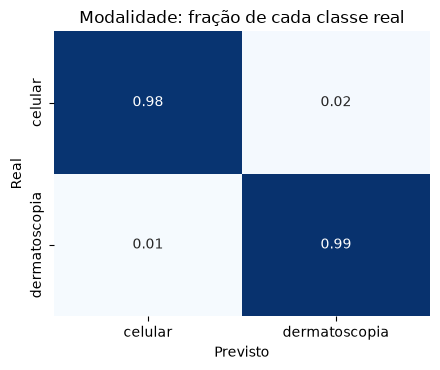

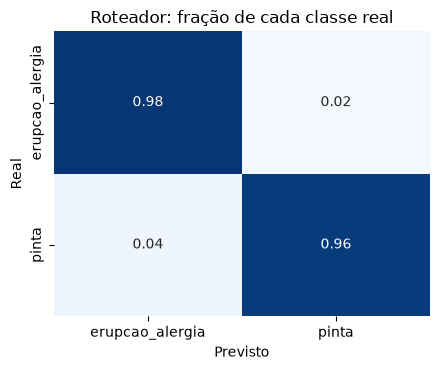

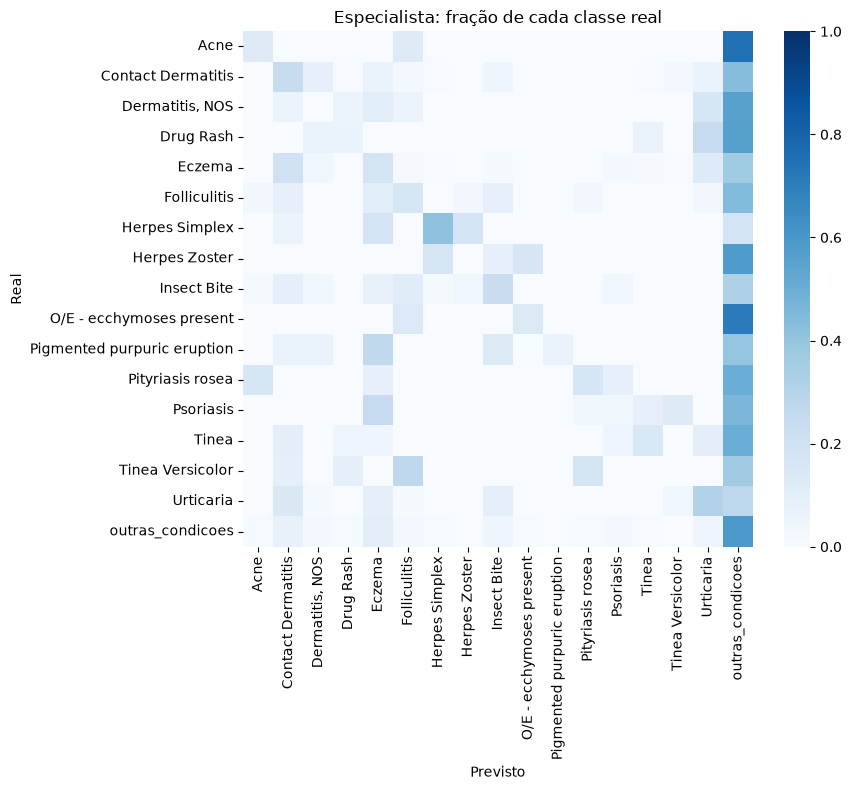

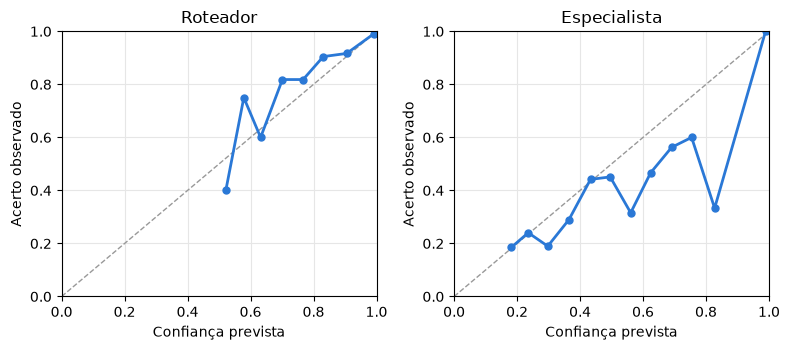

5214

In [52]:
FIGURAS.mkdir(parents=True, exist_ok=True)
metricas = {"modalidade": evaluate_modality()}
metricas["roteador"], curva_roteador = evaluate_router()
metricas["especialista"], curva_especialista, teste_esp, probs_esp, y_esp = evaluate_specialist()
metricas["sistema"], tons = evaluate_system()
metricas["tipo_de_pele"] = tone_groups(None, teste_esp, probs_esp, y_esp, tons)
plot_reliability({"Roteador": curva_roteador, "Especialista": curva_especialista})
(RELATORIOS / "metricas_triagem.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")

### Detector de modalidade e roteador

In [53]:
r = metricas["roteador"]
display(pd.Series({"Modalidade: acurácia balanceada": metricas["modalidade"]["acuracia_balanceada"],
                   **{f"Modalidade: acerto em {k}": v for k, v in metricas["modalidade"]["acuracia_por_origem"].items()},
                   "Roteador: acurácia balanceada": r["acuracia_balanceada"],
                   "Roteador: F1 pinta": r["f1_por_classe"]["pinta"],
                   "Roteador: F1 erupção/alergia": r["f1_por_classe"]["erupcao_alergia"],
                   "Roteador: fora do escopo": r["fora_do_escopo_pct"],
                   "Pintas do SCIN (teste externo): reconhecidas": r["pintas_scin_externo"]["recall_pinta"]}, name="valor").round(3).to_frame())

,valor
Modalidade: acurácia balanceada,0.986
Modalidade: acerto em SCIN,0.993
Modalidade: acerto em PAD,0.953
Modalidade: acerto em ISIC,0.991
Roteador: acurácia balanceada,0.968
Roteador: F1 pinta,0.955
Roteador: F1 erupção/alergia,0.981
Roteador: fora do escopo,0.059
Pintas do SCIN (teste externo): reconhecidas,0.057


**Resultado.** O detector de tipo de foto funciona bem (98,6% de acurácia balanceada).

O roteador acerta 96,8% no teste, **mas esse número engana**. Ele reconheceu só **2 das 35 imagens (5,7%)** de pintas do próprio SCIN, que nunca viu no treino. Ou seja, aprendeu em boa parte a diferença entre **as bases** (fotos de clínica do PAD-UFES e fotos caseiras do SCIN) e não entre pinta e erupção. É o risco previsto na arquitetura, agora medido. **Na prática, uma pinta fotografada em casa tende a ser tratada como erupção.**

### Especialista em erupções e alergias

In [54]:
e = metricas["especialista"]
display(pd.Series({k: e[k] for k in ("n_imagens", "n_casos", "acuracia", "acuracia_top3", "acuracia_por_caso", "acuracia_balanceada", "f1_macro", "auroc_macro", "sem_identificar_pct")}, name="valor").round(3).to_frame())
display(pd.DataFrame(e["comparacao_val"]).T.round(3))
pd.Series(e["sensibilidade_por_classe"], name="sensibilidade").sort_values(ascending=False).round(2).to_frame()

,valor
n_imagens,802.000
n_casos,380.000
acuracia,0.283
acuracia_top3,0.692
acuracia_por_caso,0.334
acuracia_balanceada,0.170
f1_macro,0.182
auroc_macro,0.806
sem_identificar_pct,0.106


,val_bal_acc,val_f1_macro
unico,0.263,0.231
suave,0.239,0.253


,sensibilidade
outras_condicoes,0.59
Herpes Simplex,0.41
Urticaria,0.31
Contact Dermatitis,0.24
Insect Bite,0.23
Eczema,0.18
Folliculitis,0.17
Pityriasis rosea,0.17
Tinea,0.15
O/E - ecchymoses present,0.14


**Resultado.** O especialista ainda é fraco para indicar uma única condição: 28% de acerto na primeira sugestão e 17% de acurácia balanceada (24% na validação), em 17 classes. É mais útil como lista: a condição certa aparece entre as **3 primeiras em 69%** das imagens, e o AUROC macro é 0,81. Usando as fotos do mesmo caso juntas, o acerto sobe para 33%.

A matriz de confusão mostra que boa parte dos erros cai em `outras_condicoes`. Rótulos suaves venceram por pouco na validação, pelo F1 macro. Os limites vêm da base: poucos casos por classe, rótulos incertos e fotos caseiras. A temperatura reduziu o erro de calibração (ECE) de 0,165 para 0,058.

### Sistema completo: erro grave

O erro mais grave é orientar 🟢 cuidados em casa quando o caso precisaria de 🟠 ou 🔴.

In [55]:
s = metricas["sistema"]
tabela = pd.DataFrame({"Geral": s["geral"], **s["por_origem"]}).T
display(tabela[["n", "precisa_atendimento", "erros_graves", "taxa_erro_grave", "sem_identificar_pct", "excesso_cautela"]].round(3))
print("Fotos de celular confundidas com dermatoscopia:", s["celular_confundida_com_dermatoscopia"])

,n,precisa_atendimento,erros_graves,taxa_erro_grave,sem_identificar_pct,excesso_cautela
Geral,2671.0,868.0,119.0,0.137,0.057,0.311
ISIC,1511.0,307.0,26.0,0.085,0.000,0.174
PAD,344.0,272.0,1.0,0.004,0.113,0.986
SCIN,816.0,289.0,92.0,0.318,0.137,0.531


Fotos de celular confundidas com dermatoscopia: 22


**Resultado.** A taxa geral de **erro grave é de 13,7%** (119 de 868 imagens que precisariam de atendimento), e o valor depende muito da origem:

- **Dermatoscopia (ISIC): 8,5%** (26 de 307), em linha com os 91,5% de sensibilidade do modelo de pintas neste teste. Dobrou em relação aos pesos de partida (4,2%), em troca de bem menos excesso de cautela (17,4% contra 27,3%): é o custo do ponto de operação escolhido, ver a tabela de limiares na seção 3.
- **PAD-UFES: 0,4%**, porque toda pinta de celular recebe orientação de avaliação médica.
- **SCIN: 31,8%** (92 de 289). É o ponto mais preocupante: uma condição que exigiria consulta frequentemente é confundida com outra de cuidados em casa.

A referência parte de rótulos incertos, e as perguntas de alerta, que elevariam a urgência em parte desses casos, não foram respondidas nesta medida. Mesmo assim, **este sistema não está pronto para orientar pessoas em fotos caseiras**.

### Desempenho por tipo de pele

In [56]:
t = metricas["tipo_de_pele"]
display(pd.DataFrame(t["monk"]).T.round(3))
display(pd.DataFrame(t["fitzpatrick"]).T.round(3))
pd.DataFrame(t["erro_grave_por_monk"]).T.round(3)

,imagens,casos,acuracia,acuracia_top3,acuracia_balanceada
1-2,381.0,178.0,0.270,0.698,0.177
3-4,314.0,151.0,0.261,0.691,0.172
5-6,83.0,40.0,0.289,0.590,0.154
7-10,20.0,9.0,0.800,1.000,0.733


,imagens,casos,acuracia,acuracia_top3,acuracia_balanceada
I-II,153.0,66.0,0.320,0.706,0.183
III-IV,190.0,84.0,0.242,0.611,0.167
V-VI,87.0,35.0,0.299,0.747,0.178


,precisa_atendimento,taxa
1-2,136.0,0.279
3-4,101.0,0.426
5-6,37.0,0.243
7-10,15.0,0.133


**Resultado.** Não há diferença clara entre tons de pele na acurácia balanceada do especialista (15% a 18% nos grupos com dados suficientes), mas o número de casos é pequeno. Monk 7 a 10 tem só 9 casos, e os 80% ali não têm valor estatístico. Em erros graves, Monk 3-4 teve a maior taxa (43%, contra 28% em Monk 1-2). A base tem poucos tons escuros, portanto **não dá para afirmar que o sistema é justo entre tons de pele**.

### Grad-CAM

Onde o especialista olhou em casos do teste (fotos em close, de adultos, sem tronco nem região genital). Na maior parte, o mapa cai sobre a pele afetada e não no fundo ou em roupas. A amostra é pequena e o mapa tende ao centro da imagem, porque o recorte central favorece isso.

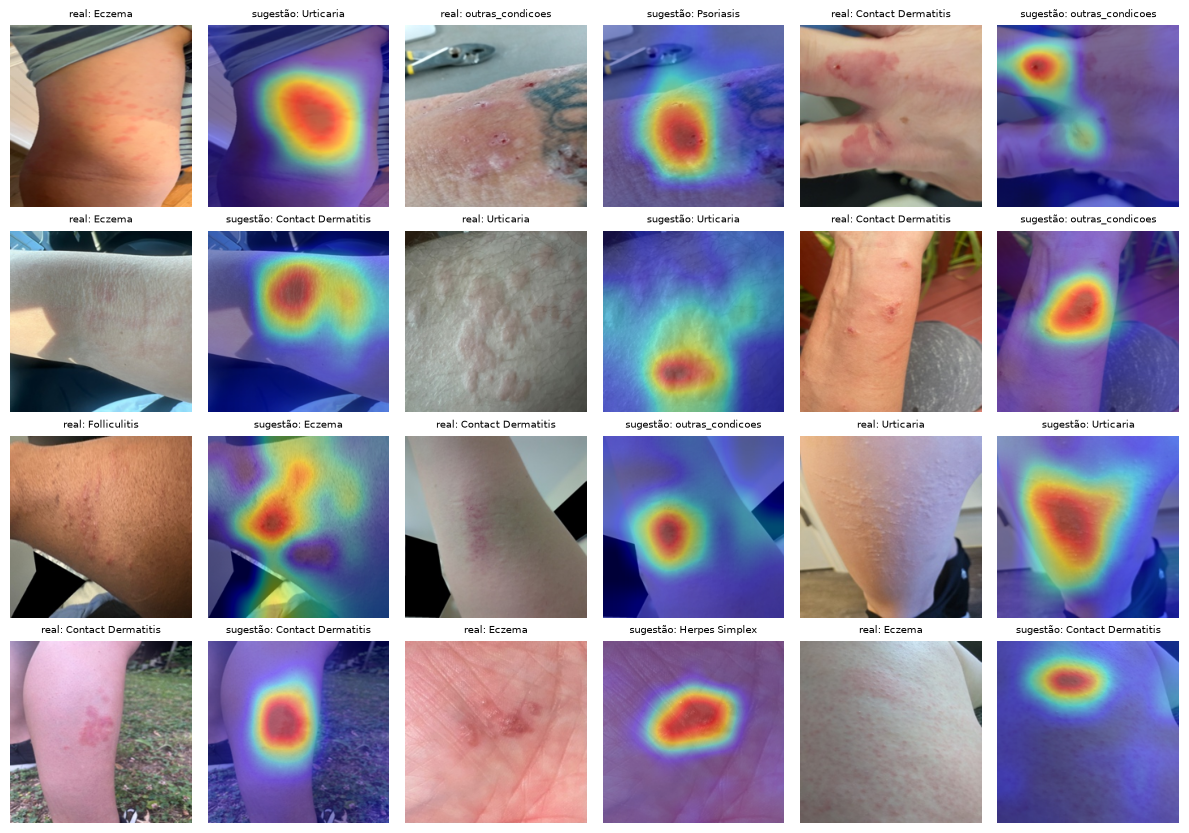

In [57]:
plot_grad_cam(teste_esp, probs_esp)

# Registro de iterações

## Iteração 1: EfficientNetV2-B0, 224 px, na CPU (07/11/2026)

*Hoje estes são só os pesos de partida do modelo do projeto (iteração 4).*

**Configuração**: EfficientNetV2-B0 pré-treinada no ImageNet + metadados (idade, sexo, região do corpo); imagens com Shades of Gray, 224 px; fase 1 de 2 épocas só com a cabeça; fase 2 com ajuste fino da rede inteira com BatchNormalization congeladas, AdamW (lr de pico 3e-4, weight decay 0,02), aquecimento + cosseno, até 20 épocas com parada antecipada (paciência 5), batch 32; ajuste de prior com tau escolhido na validação; TTA de 8 visões.

**Treino**: ~7 h na CPU, com duas interrupções por falta de memória (retomado do backup). A melhor época foi a 11ª do ajuste fino; a parada antecipada encerrou o treino na 18ª.

| Variante | Acurácia balanceada (val, 8 classes) | Acurácia (teste) | Acurácia balanceada (teste, 7 classes) | AUC maligno × benigno (teste) |
|---|---|---|---|---|
| Fase 1: rede congelada (baseline) | 51,9% | 67,1% | 47,7% | 0,867 |
| Fase 2: ajuste fino | 66,1% | 81,8% | 72,4% | 0,938 |
| **Fase 2 + TTA (final)** | **66,3%** | **82,2%** | **74,3%** | **0,943** |

**Comparação com dermatologistas** (mesmas 1.412 imagens do teste, Tschandl et al., *Nature Medicine* 2020):

| | Acurácia | Acurácia balanceada |
|---|---|---|
| Dermatologistas sem IA | 69,4% | 71,4% |
| Dermatologistas com a IA do estudo | 74,4% | 75,4% |
| IA do estudo | 78,2% | 77,7% |
| **Nosso professor** | **76,7%** | **74,1%** |

**Triagem maligno × benigno**: com o limiar escolhido na validação para 95% de sensibilidade, o teste teve **95,8% de sensibilidade** e 73,3% de especificidade.

**Observações**
- O ajuste fino é o que mais pesa: +27 pontos de acurácia balanceada no teste sobre o baseline de embeddings congelados. O TTA soma cerca de +2 pontos.
- O professor já supera a média dos dermatologistas sem apoio da IA, mas ainda fica abaixo da IA do estudo.
- **Ponto fraco: melanoma**, com só 50% de sensibilidade quando a lesão é classificada sozinha. 22% dos melanomas saem como nevo e 14% como bkl. Na triagem com limiar de 95%, quase todos os casos malignos são sinalizados, mas a classe exata do melanoma ainda erra muito. O `df` também é confundido com nevo (23%).
- **Overfitting**: depois da época 8, a perda de validação sobe enquanto a de treino cai até 0,13. A acurácia balanceada estabiliza em ~64–66%. Mais regularização deve ajudar.
- **Por origem**: na validação, as imagens do BCN são as mais difíceis (64,5% de acurácia, contra 85% no HAM), e o teste vem todo do HAM. O BCN tem mais melanomas e lesões atípicas.
- A validação tem 8 classes, separando `ak` e `scc`, e o teste tem 7, com `akiec` juntando as duas. Por isso a acurácia balanceada do teste é maior.

**Próximos passos**
1. **Resolução e rede maiores na GPU do Kaggle** (EfficientNetV2-S, 384 px; `kaggle_professor.ipynb`): o maior ganho esperado, principalmente em melanoma, que depende de detalhes finos.
2. **Regularização contra o overfitting**: Mixup/CutMix, stochastic depth, EMA dos pesos.
3. **Ensemble** de professores com arquiteturas diferentes.
4. **Pseudo-rótulos** nas 6.726 imagens sem rótulo, que depois alimentam o aluno.

## Iteração 2: ajuste para foto de celular com simulação (08/11/2026)

**Motivação**: o professor da iteração 1, avaliado em bases que não viu, mantém AUC de melanoma 0,91 em dermatoscopia nova (ISIC 2019 teste, MILK10k) mas cai para 0,59 em fotos de celular (PAD-UFES-20 + HIBA).

**Configuração**: ajuste fino do `professor_effv2b0` (BatchNormalization congeladas, AdamW lr 1e-4 com aquecimento + cosseno, batch 32, até 8 épocas, paciência 3; melhor época a 7ª) em 23.435 imagens sem celular: ISIC 2019 treino, ISIC 2020, MILK10k dermatoscopia e *close-up*, MED-NODE, MSKCC e anônimas da ISIC, com nevos limitados a 6.000. Augmentation do pipeline + **simulação de celular** (recorte da borda, afastamento, cor forte, balanço de branco, sombra, resolução, desfoque, ruído, JPEG). Validação só nas mesmas bases (6.285 imagens), tau 1,1 e limiar 0,287 escolhidos nela. Três variantes: A só dermatoscopia + simulação; **B dermatoscopia + fotos de câmera + simulação**; C igual a B sem simulação (controle). ~2,5 h cada na CPU.

**Teste em fotos de celular** (PAD-UFES-20 + HIBA inteiras, 2.643 fotos, 117 melanomas, nenhuma vista no treino):

| Modelo | AUC melanoma | Sens. melanoma | Precisão melanoma | Acurácia balanceada | Triagem sens. / espec. |
|---|---|---|---|---|---|
| Professor da iteração 1 | 0,593 | 22% | 7% | 30% | 92% / 49% |
| A: só dermatoscopia + simulação | 0,735 | 26% | 13% | 40% | 91% / 61% |
| **B: + fotos de câmera + simulação (salvo em `modelos/`)** | **0,871** | **50%** | **22%** | **48%** | 97% / 41% |
| C: igual a B, sem simulação (controle) | 0,827 | 47% | 26% | 46% | 96% / 49% |

**Observações**
- A simulação de celular ajuda (B × C: +0,044 de AUC de melanoma, +3 pontos de sensibilidade), mas a maior parte do ganho vem de incluir fotos clínicas comuns no treino: só dermatoscopia + simulação (A) recupera menos da metade do caminho.
- No PAD-UFES-20 o B chega a AUC 0,915 e 67% de sensibilidade de melanoma; na HIBA, 0,817 e 37%. Na dermatoscopia empata com o professor da iteração 1 (iteração 4).
- O limiar de triagem transferido da validação em dermatoscopia fica agressivo no celular: 97% de sensibilidade mas 41% de especificidade (6 em 10 benignos encaminhados). Com limiar 0,5 fica em 91% / 62%. Precisa ser calibrado em foto de celular, com um conjunto separado do teste.
- A acurácia simples segue baixa (39%) porque o teste é dominado por `ak` e `bcc` em pele fotoenvelhecida, com muita confusão `ak` ↔ `bkl` ↔ `scc`. 58 dos 117 melanomas ainda recebem outra classe (`bkl` 17, `vasc` 16, `nv` 10, `df` 7); o `vasc`, classe rara inflada pelo ajuste de prior, é suspeito.
- Para comparação, um ajuste fino **com** fotos de celular no treino (não incluído no repositório) chegou a AUC de melanoma 0,96 num teste menor (401 fotos): dado real de celular ainda vale mais do que simulá-lo.

**Próximos passos**
1. Juntar as duas coisas: receita B (fotos + simulação) e depois ajuste fino com as fotos de celular disponíveis, guardando uma parte só para teste.
2. Calibrar tau e limiar de triagem em foto de celular.
3. Mais fotos de celular rotuladas (MRA-MIDAS, DDI; SCIN para lesões inflamatórias) e atacar a confusão `ak`/`bkl`/`scc`.

## Iteração 3: triagem em duas etapas (09/11/2026)

*Medida ainda com os pesos da iteração 1 na rota de dermatoscopia; os valores atuais estão na iteração 4.*

**Configuração**: SCIN (25 de 26 arquivos; 2.581 casos limpos) e PAD-UFES-20 (2.283 imagens). EfficientNetV2-B0, 224 px, na CPU, em ~2h30. Detector de modalidade só com a cabeça; roteador e especialista com ajuste fino, peso por classe, calibração e limiar de confiança na validação.

| | Métrica no teste | Valor |
|---|---|---|
| Detector de modalidade | acurácia balanceada | 98,6% |
| Roteador | acurácia balanceada | 96,8% |
| Roteador | pintas do SCIN reconhecidas (teste externo) | **5,7%** |
| Especialista (17 classes) | acerto top-1 / top-3 | 28,3% / 69,2% |
| Especialista | acurácia balanceada / F1 macro / AUROC | 17,0% / 18,2% / 0,81 |
| Sistema | erro grave (🟢 quando precisava de 🟠 ou 🔴) | **12,2%** (SCIN: 31,8%) |

**Observações**
- O roteador aprendeu mais a origem da foto do que o tipo de lesão: acerta quase tudo dentro das bases e falha nas pintas do SCIN.
- Sem classes de queimadura e ferida (4 e 30 casos).
- Falta o arquivo `train-00000-of-00026.parquet` do SCIN (~4% da base).

**Próximos passos**
1. **Reduzir o erro grave**: somar a probabilidade das condições que pedem consulta e escolher na validação um limiar de alta sensibilidade, como na triagem de pintas (a medir em um teste novo, já que este foi usado).
2. **Fotos caseiras de pintas** de outras fontes, para o roteador não aprender a origem.
3. **Bases específicas** de queimaduras e feridas.
4. **Mais dados e resolução maior** para o especialista, e o arquivo que falta do SCIN.
5. **Revisão das orientações por um profissional de saúde.**

## Iteração 4: um único modelo no projeto (09/11/2026)

**Decisão**: o modelo da iteração 2 passa a ser o único modelo de pintas do projeto, em todas as rotas. Os pesos da iteração 1 ficam só como ponto de partida para retreinar (`modelos/pintas/pesos_de_partida.keras`).

**Por quê**: faltava medir o modelo novo em dermatoscopia, e ele empata com o anterior, enquanto no celular ganha com folga.

| Teste | Métrica | Pesos de partida | Modelo do projeto | IC 95% da diferença |
|---|---|---|---|---|
| Dermatoscopia (ISIC 2018) | acurácia | 82,2% | **82,8%** | −1,1 a +2,3 pontos |
| Dermatoscopia (ISIC 2018) | acurácia balanceada | 74,3% | **75,0%** | −2,4 a +3,6 pontos |
| Dermatoscopia (ISIC 2018) | AUC maligno × benigno | 0,943 | **0,945** | −0,006 a +0,012 |
| Dermatoscopia (ISIC 2018) | sensibilidade de melanoma | 50% | **62%** | |
| Celular (PAD-UFES-20 + HIBA) | acurácia | 31,5% | **38,9%** | +5 a +9 pontos |
| Celular (PAD-UFES-20 + HIBA) | acurácia balanceada | 30,3% | **47,8%** | +14 a +21 pontos |
| Celular (PAD-UFES-20 + HIBA) | AUC de melanoma | 0,593 | **0,871** | +0,23 a +0,32 |
| Celular (PAD-UFES-20 + HIBA) | AUC maligno × benigno | 0,845 | **0,868** | +0,01 a +0,04 |

**Comparação com dermatologistas** (mesmas 1.412 imagens): nosso modelo faz 76,3% de acurácia e 75,0% de acurácia balanceada; dermatologistas sem IA, 69,4% e 71,4%; IA do estudo, 78,2% e 77,7%.

**O que mudou no projeto**
- `pipeline.simular_celular` agora é o código comum da simulação de celular, usado pelo script de treino e demonstrado na seção 2.
- Uma pasta só para o modelo: `modelos/pintas/`. O notebook não treina, carrega as previsões salvas e reavalia.
- Na triagem, a pinta em foto de celular também passa pelo modelo, que sugere classes e ajusta o texto, mas a urgência continua sempre "consulta em breve".
- `tau` 1,1, prior do novo treino e limiar 0,287 também na rota de dermatoscopia.

**Efeito na triagem**

| | Erro grave | Excesso de cautela |
|---|---|---|
| Dermatoscopia, antes | 4,2% (13 de 307) | 27,3% |
| **Dermatoscopia, agora** | **8,5% (26 de 307)** | **17,4%** |
| Sistema inteiro, antes | 12,2% (106 de 868) | 37,7% |
| **Sistema inteiro, agora** | **13,7% (119 de 868)** | **31,1%** |

PAD-UFES (0,4%) e SCIN (31,8%) não mudam: a urgência nessas rotas não depende do modelo de pintas.

**Observações**
- O limiar 0,287 dá 95,8% de sensibilidade na validação e 91,5% no teste. Calibrar só em dermatoscopia não ajudou (0,314, 89,6% no teste); a queda vem da mudança de base.
- A comparação das variantes da iteração 2 usou o teste de celular, então os números de celular podem estar levemente otimistas.
- Na simulação, o fundo do efeito "afastar" sai como retângulo cinza de borda marcada e a borda artificial do dermatoscópio continua em 25% das imagens.

**Próximos passos**
1. **Decidir o limiar de triagem** em dermatoscopia, de preferência em um conjunto novo: 0,20 daria 94,8% de sensibilidade e 76,0% de especificidade neste teste, mas agora ele já foi visto.
2. **Aplicar a simulação ao roteador**, que ainda aprende a origem das fotos (reconhece 5,7% das pintas do SCIN): pintas de dermatoscopia com aparência de celular podem ajudar.
3. **Corrigir a simulação** (fundo do "afastar", borda artificial) e retreinar.
4. Ajuste fino com fotos de celular reais, guardando uma parte só para teste.
